<hr style="border-width:2px;border-color:red">
<center><h1> Projet Data : Assurance Automobile </h1></center>
<center><h2> DIENG Moussa & CISSE Oumar </h2></center>
<center><h2>  M2 IMSA  2025-2026 </h2></center>
<hr style="border-width:2px;border-color:red">


# Introduction

Dans le cadre de ce projet, nous avons étudié un **jeu de données d’assurance automobile** issu de la base **Fremotor**, portant sur un portefeuille privé observé entre **janvier 2003 et décembre 2004**. L’objectif général est de mettre en place une démarche complète allant du **traitement des données** jusqu’à la **modélisation de la sinistralité** et à une première réflexion sur la **tarification**.

Le jeu de données est structuré en **trois tables principales** :

- **Table des primes (`fremotor1prem0304a`)** :  
  elle contient les informations relatives aux polices d’assurance, aux caractéristiques du conducteur et du véhicule, ainsi qu’aux **primes annuelles** associées aux différentes garanties.

- **Table des fréquences de sinistres (`fremotor1freq0304a`)** :  
  elle renseigne le **nombre de sinistres par garantie**, pour chaque police d’assurance et par **année d’observation**.

- **Table de sévérité des sinistres (`fremotor1sev0304a`)** :  
  elle contient le **montant payé pour chaque sinistre**, la **date de survenance**, la **garantie concernée** ainsi que l’**identifiant du sinistre**.

Compte tenu de cette structure, chaque table a d’abord été traitée séparément afin de :
- détecter et corriger les **anomalies, incohérences et doublons éventuels** ;
- mettre les variables dans un **format exploitable** pour l’analyse statistique et la modélisation ;
- harmoniser les informations issues des différentes sources afin de construire une **base finale cohérente**.

Cette phase de préparation est essentielle, car la qualité des résultats dépend directement de la fiabilité des données mobilisées. Une fois la base nettoyée et restructurée, l’étude s’organise autour de plusieurs étapes complémentaires : une **analyse exploratoire des données**, une **modélisation paramétrique et non paramétrique** de la sinistralité, puis une **approche de tarification** fondée sur la fréquence et la sévérité des sinistres.

Ainsi, ce projet s’inscrit à la fois dans une logique de **data analysis**, de **machine learning appliqué à l’assurance** et de **tarification actuarielle**, avec pour objectif final de mieux comprendre les déterminants du risque automobile.


# I. Traitement des Données

## 1. Table fréquence

In [1]:
# importation des données
import pandas as pd
frequence = pd.read_csv('fremotor1freq0304a.csv', sep=';')
# affichage des dimensions de la table frequence
print("Dimensions de la table frequence:", frequence.shape)

# affichage de la table 
frequence.head()


Dimensions de la table frequence: (8479, 8)


,IDpol,Year,Damage,Fire,Other,Theft,TPL,Windscreen
0,90161362.100a,2003,0,0,0,0,1,0
1,90173099.100b,2003,0,0,0,0,0,1
2,90122250.101b,2004,1,0,0,0,1,0
3,90112045.101c,2004,0,0,0,0,0,1
4,90144800.100a,2004,0,0,0,1,0,0


l'étude concerne que les polices de l'échantillon a donc nous allons resteindre notre perimétre d'études en gardant les identité de polices terminant par '_a', sera valable pour les autres tables, prime et montant des sinistres.

In [2]:
# filtrer le jeu sur l'échantillon a , idpol terminant par a
frequence = frequence[frequence['IDpol'].str.endswith('a')]
# affichage des dimensions de la table frequence_a
print("Dimensions de la table frequence:", frequence.shape)


Dimensions de la table frequence: (5975, 8)


In [3]:
frequence.info() 

<class 'pandas.core.frame.DataFrame'>
Index: 5975 entries, 0 to 8478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   IDpol       5975 non-null   object
 1   Year        5975 non-null   int64 
 2   Damage      5975 non-null   int64 
 3   Fire        5975 non-null   int64 
 4   Other       5975 non-null   int64 
 5   Theft       5975 non-null   int64 
 6   TPL         5975 non-null   int64 
 7   Windscreen  5975 non-null   int64 
dtypes: int64(7), object(1)
memory usage: 420.1+ KB


- Nous n'avons aucune donnée manquante pour la table des fréquences des sinistres, notre jeu de données est complet.
- Le typage des variables est correcte vu la documentation du jeu de données. 


In [4]:
# vérification des doublons  sachant que l'identifiant unique est 'IDpol' et 'Year'
print("Doublons dans frequence:", frequence.duplicated(subset=['IDpol', 'Year']).sum())

# suppression des doublons
frequence = frequence.drop_duplicates(subset=['IDpol', 'Year'])
print("Dimensions de la table frequence après suppression des doublons:", frequence.shape)

Doublons dans frequence: 4
Dimensions de la table frequence après suppression des doublons: (5971, 8)


Pour la table fréquence, la clé primaire est le couple (IDpol, Year), on a 4 doublons et on va les supprimer de notre table. 

#### Vérification des valeurs inchorérentes

In [5]:
# Statistiques descriptives pour les variables numériques 
freq_quanti= frequence.drop(columns=['IDpol'])
cols = freq_quanti.columns
for col in cols : 
    print(freq_quanti[col].value_counts())

Year
2004    3102
2003    2868
2005       1
Name: count, dtype: int64
Damage
0    5308
1     651
2      12
Name: count, dtype: int64
Fire
0    5897
1      74
Name: count, dtype: int64
Other
0    5819
1     152
Name: count, dtype: int64
Theft
0    5549
1     418
2       3
3       1
Name: count, dtype: int64
TPL
0    3128
1    2703
2     134
3       5
4       1
Name: count, dtype: int64
Windscreen
 0    3758
 1    2150
 2      60
-1       2
 3       1
Name: count, dtype: int64


Observation : 
- L'étude concerne les polices d'assurances enrégistré entre 2003 et 2004, donc 2005 est une valeur inchoérente, nous allons donc supprimer les sinistres enrégistré en 2005 dans la table des fréquences.
- **Valeur négative pour `Windscreen`** : la variable représentant le **nombre de sinistres Bris de glace** contient une valeur **–1**, ce qui est incohérent puisqu’il s’agit d’un **compte de sinistres**, doivent être **supérieur ou égal à 0**.

Deux options de traitement sont envisageables :
1. **Supprimer les observations concernées**, afin de conserver une stricte cohérence des données ;  
2. **Corriger la valeur –1 en 1**, si l’on considère qu’il s’agit d’une erreur de saisie correspondant vraisemblablement à un sinistre déclaré.

Compte tenu du caractère très marginal de cette anomalie, la correction ou la suppression de ces observations aura un impact limité sur l’analyse globale et nous décidons de les corriger. 


In [6]:
# supression des lignes coresspondant à l'année 2005
frequence = frequence[frequence['Year'] != 2005]
# verif 
print("Valeurs uniques pour Year après correction :\n", frequence['Year'].unique())


# remplacement de la valeur -1 par 1 de Windscreen
frequence['Windscreen'] = frequence['Windscreen'].replace(-1, 1)    
# vérification de la correction
print("Valeurs uniques pour Windscreen après correction :\n", frequence['Windscreen'].unique())

Valeurs uniques pour Year après correction :
 [2003 2004]
Valeurs uniques pour Windscreen après correction :
 [0 1 2 3]


In [7]:
# Table de fréquence propre 
freq = frequence.copy() 
freq.head(), freq.shape

(           IDpol  Year  Damage  Fire  Other  Theft  TPL  Windscreen
 0  90161362.100a  2003       0     0      0      0    1           0
 4  90144800.100a  2004       0     0      0      1    0           0
 6  90133546.100a  2004       1     0      0      0    0           0
 7  90187046.100a  2004       0     0      0      0    0           1
 8  90110914.102a  2004       0     0      0      0    1           0,
 (5970, 8))

## 2. Table prime

In [8]:
# importation 
prime = pd.read_csv('fremotor1prem0304a.csv', sep=';')
# affichage des dimensions de la table prime
print("Dimensions de la table prime:", prime.shape)
# affichage de la table 
prime.head()

Dimensions de la table prime: (51968, 30)


,IDpol,Year,DrivAge,DrivGender,MaritalStatus,BonusMalus,LicenceNb,PayFreq,JobCode,VehAge,...,PremDamAll,PremFire,PremAcc1,PremAcc2,PremLegal,PremTPLM,PremTPLV,PremServ,PremTheft,PremTot
0,90133908.100a,2003,34.0,F,NaN,"50,00",2,Quarterly,NaN,1,...,146,7,0,0,8,"97,7",5,57,66,"412,7"
1,90103626.10a,2003,31.0,M,Cohabiting,"95,00",2,Monthly,Retiree,7,...,0,40,40,0,26,"622,7",33,55,461,"1454,7"
2,90116867.101a,2004,30.0,M,Cohabiting,"64,00",2,Half-yearly,Public employee,12,...,0,7,0,0,12,"197,7",11,56,73,"381,7"
3,1009305.100c,2004,38.0,M,Single,"68,00",2,Half-yearly,Private employee,7,...,0,0,0,0,15,"268,4",14,62,0,"359,4"
4,90161239.100d,2004,40.0,F,NaN,"65,00",2,Half-yearly,NaN,11,...,0,0,0,58,13,"220,2",12,57,0,"360,2"


L'étude concerne les polices de l'échantillon "a", on filtre notre jeu de données

In [9]:
# filtrer le jeu sur l'échantillon a , idpol terminant par a
prime = prime[prime['IDpol'].str.endswith('a')]
# affichage des dimensions de la table prime_a
print("Dimensions de la table prime:", prime.shape)
print(prime)

Dimensions de la table prime: (30791, 30)
               IDpol  Year  DrivAge DrivGender MaritalStatus BonusMalus  \
0      90133908.100a  2003     34.0          F           NaN      50,00   
1       90103626.10a  2003     31.0          M    Cohabiting      95,00   
2      90116867.101a  2004     30.0          M    Cohabiting      64,00   
6      90182035.100a  2004     38.0          M           NaN      50,00   
7      90176250.100a  2004     45.0          F           NaN      50,00   
...              ...   ...      ...        ...           ...        ...   
51960   1009432.101a  2003     32.0          M       Married      80,00   
51961  90145885.100a  2003     44.0          M           NaN      56,00   
51964  90185196.100a  2003     45.0          M           NaN      58,00   
51966  90111262.101a  2004     39.0          M    Cohabiting      50,00   
51967   1005352.100a  2004     45.0          M    Cohabiting      69,00   

       LicenceNb      PayFreq           JobCode  VehAge  

on constate déja une anomalie sur les variables PremTPLM et PremTot, BonusMalus. D base python utilise des codages en anglais donc pour les nombres décimales, les séparateurs sont des points au lieu de virgules, nous allons donc corriger ça en remplaçant les virgules par point.  

In [10]:
# vérification des doublons sachant que l'identifiant unique est 'IDpol' et 'Year'
print("Doublons dans prime:", prime.duplicated(subset=['IDpol', 'Year']).sum())
# suppression des doublons
prime = prime.drop_duplicates(subset=['IDpol', 'Year'])
print("Dimensions de la table prime après suppression des doublons:", prime.shape)


Doublons dans prime: 12
Dimensions de la table prime après suppression des doublons: (30779, 30)


In [ ]:
# remplacer le ","" par "."" dans la variable PremTPLM et PremTot
# Liste des variables à corriger
cols = ['PremTPLM', 'PremTot', 'BonusMalus']
for col in cols:
    prime[col] = (
        prime[col]
        .astype(str)                # s'assurer que tout est en string
        .str.replace(',', '.', regex=False)  # remplacer virgule par point
        .astype(float)              # convertir en float
    )

# Vérification
print(prime[['PremTPLM', 'PremTot']].dtypes)
print(prime[['PremTPLM', 'PremTot']].head())


PremTPLM    float64
PremTot     float64
dtype: object
   PremTPLM  PremTot
0      97.7    412.7
1     622.7   1454.7
2     197.7    381.7
6     107.1    374.1
7     130.7    389.7


In [12]:
prime.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30779 entries, 0 to 51967
Data columns (total 30 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   IDpol           30779 non-null  object 
 1   Year            30779 non-null  int64  
 2   DrivAge         30779 non-null  float64
 3   DrivGender      30774 non-null  object 
 4   MaritalStatus   9939 non-null   object 
 5   BonusMalus      30779 non-null  float64
 6   LicenceNb       30779 non-null  int64  
 7   PayFreq         30779 non-null  object 
 8   JobCode         9939 non-null   object 
 9   VehAge          30779 non-null  int64  
 10  VehClass        30779 non-null  object 
 11  VehPower        30779 non-null  object 
 12  VehGas          30779 non-null  object 
 13  VehUsage        30779 non-null  object 
 14  Garage          30779 non-null  object 
 15  Area            30779 non-null  object 
 16  Region          30779 non-null  object 
 17  Channel         30779 non-null  obje

Notre jeu de données contient un nombre non négligeable de données manquantes notamment sur les variables DriveGender, CodeJob, Maritalstatus que nous allons traiter.
Par ailleurs, certaines variables ne sont pas correctement typées au regard de la documentation du jeu de données.
Nous procéderons donc à leur traitement et correction, en justifiant les choix méthodologiques retenus dans la suite de ce travail.

In [13]:
# afficher les pourcentage de valeurs manquantes que dans les variables qui contiennent des valeurs manquantes
missing_percentage = prime.isnull().mean() * 100
missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)
print("Pourcentage de valeurs manquantes pour les variables concernées:\n", missing_percentage)

Pourcentage de valeurs manquantes pour les variables concernées:
 MaritalStatus    67.708503
JobCode          67.708503
DrivGender        0.016245
dtype: float64



- Le  genre du conducteur `DriveGender`avec une faible pourcentage presque nulle (0%)
- Le type d'emploi  du conducteur `CodeJob` et la situation familiale du conducteur `Maritalstatus`contiennent, plus de la moitié des observations sont manquantes sur ces variables 34000 sur 51000. Ils ont les même nombre de données manquantes. 

In [14]:
# Vérification si les indices des données manquantes sont identiques
missing_indices_equal = prime['JobCode'].isnull().equals(prime['MaritalStatus'].isnull())
print("Les deux variables 'CodeJob' et 'MaritalStatus' ont-elles les mêmes indices de données manquantes ? :", missing_indices_equal)

Les deux variables 'CodeJob' et 'MaritalStatus' ont-elles les mêmes indices de données manquantes ? : True


De plus, ces deux variables présentent des valeurs manquantes aux mêmes indices, ce qui indique que les données sont absentes simultanément. Étant donné le nombre important de valeurs manquantes et le fait que les informations disponibles dans les autres variables ne permettent pas une imputation fiable, nous décidons de supprimer ces deux variables de la table.
Par ailleurs, nous considérons que le type d’emploi et la situation familiale du conducteur n’ont pas d’impact significatif sur le montant des primes dans le cadre de cette étude.

In [15]:
# suppression des variables 'JobCode' et 'MaritalStatus' de la table prime
prime = prime.drop(columns=['JobCode', 'MaritalStatus'])    
# suppression des valeurs manqauntes pour la varable Drivegender
prime = prime.dropna(subset=['DrivGender'])
# affichage des dimensions de la table prime après suppression des valeurs manquantes
print("Dimensions de la table prime après suppression des valeurs manquantes:", prime.shape)


Dimensions de la table prime après suppression des valeurs manquantes: (30774, 28)


In [16]:
# vérification des valeurs inchoérentes
# statistiques descriptives des variables numériques
print(prime.describe())


               Year       DrivAge    BonusMalus     LicenceNb        VehAge  \
count  30774.000000  30774.000000  30774.000000  30774.000000  30774.000000   
mean    2003.352570     39.817963     63.040619      1.888672      7.712257   
std        0.477778     11.875572     15.453028      0.673787      4.739430   
min     2003.000000     18.000000     50.000000      1.000000      0.000000   
25%     2003.000000     31.000000     50.000000      1.000000      4.000000   
50%     2003.000000     38.000000     57.000000      2.000000      7.000000   
75%     2004.000000     47.000000     72.000000      2.000000     10.000000   
max     2004.000000     96.000000    156.000000      7.000000     89.000000   

       PremWindscreen    PremDamAll      PremFire      PremAcc1      PremAcc2  \
count    30774.000000  30774.000000  30774.000000  30774.000000  30774.000000   
mean        24.905082     80.506272      4.224508     12.401280     15.301326   
std         20.116618    103.133620      4.28

#### vérification des valeurs inchoérentes

In [17]:
# modalité des variables catégorielles et fréquences sauf la variable IDpol
categorical_vars = prime.select_dtypes(include=['object']).columns.drop('IDpol')
for var in categorical_vars:
    print(f"Modalités et fréquences pour la variable '{var}':")
    print(prime[var].value_counts())
    print("\n")

Modalités et fréquences pour la variable 'DrivGender':
DrivGender
M    20167
F    10604
H        3
Name: count, dtype: int64


Modalités et fréquences pour la variable 'PayFreq':
PayFreq
Half-yearly    17021
Annual         10637
Quarterly       2271
Monthly          845
Name: count, dtype: int64


Modalités et fréquences pour la variable 'VehClass':
VehClass
Cheapest          10930
Cheaper            8987
Cheap              5222
Medium low         3165
Medium             1132
Medium high         820
Expensive           326
More expensive      141
Most expensive       51
Name: count, dtype: int64


Modalités et fréquences pour la variable 'VehPower':
VehPower
P10    5502
P12    4954
P11    4837
P9     3999
P13    3759
P8     3196
P14    2182
P15     844
P7      591
P16     440
P5      387
P4       36
P17      29
P2       11
10        4
P6        1
11        1
13        1
Name: count, dtype: int64


Modalités et fréquences pour la variable 'VehGas':
VehGas
Regular    18869
Diesel     118

### Traitement des valeurs incohérentes dans la table des primes

L’analyse des variables catégorielles de la table des primes a permis d’identifier plusieurs
modalités incohérentes par rapport à la documentation officielle du jeu de données. Ces
incohérences sont principalement dues à des erreurs de saisie ou de normalisation.

#### Variable `DrivGender`
La variable `DrivGender`, représentant le genre du conducteur, ne devrait contenir que deux
modalités. Or, une modalité supplémentaire `H` apparaît avec 3 observations. Cette valeur est
incohérente et peut être attribuée à une erreur de saisie.  
Nous décidons donc de **recoder la modalité `H` en `M`**.

#### Variable `VehPower`
Pour la variable `VehPower` réprésentant la puissance du véhicule, certaines modalités apparaissent sous la forme numérique
`10`, `11` et `13`, alors que la documentation indique que les valeurs doivent être codées sous la
forme `P2` à `P15`.  
Ces modalités sont donc considérées comme des erreurs de saisie et sont **recodées respectivement
en `P10`, `P11` et `P13`**.

#### Variable `Area`
La variable `Area` contient la modalité `5`, qui est incohérente avec le format attendu. Selon le
dictionnaire des variables, les modalités doivent être préfixées par la lettre `A`.  
Nous décidons donc de **remplacer la valeur `5` par `A5`**.

#### Variable `VehGas`
L’analyse des modalités de la variable `VehGas` met en évidence plusieurs valeurs incohérentes
présentes à de très faibles fréquences :

- `Elec.`
- `Reg.`
- `Gazole`

Ces valeurs ne sont pas conformes à la documentation et peuvent être attribuées à des erreurs de
saisie ou de normalisation. Nous proposons la stratégie suivante :

- Regrouper la modalité `Reg.` avec `Regular`
- Regrouper la modalité `Gazole` avec `Diesel`
- Supprimer ou recoder la modalité `Elec.` selon la stratégie retenue, en raison de sa très faible
  fréquence et de son absence dans la documentation

Ces traitements permettent d’assurer la cohérence des variables catégorielles et d’améliorer la
qualité du jeu de données avant l’analyse.


In [18]:
# Correction des modalités de DrivGender et VehPower
prime['DrivGender'] = prime['DrivGender'].replace('H', 'M')

prime['VehPower'] = prime['VehPower'].replace({
    '10': 'P10',
    '11': 'P11',
    '13': 'P13'
})

prime[['DrivGender', 'VehPower']].head()

,DrivGender,VehPower
0,F,P11
1,M,P16
2,M,P12
6,M,P13
7,F,P12


In [19]:
# Correction des modalités de Area et VehGas
prime['Area'] = prime['Area'].replace('5', 'A5')

prime['VehGas'] = prime['VehGas'].replace({
    'Reg.': 'Regular',
    'Gazole': 'Diesel'
})

# La modalité électrique n'est pas conservée car elle n'est pas documentée proprement ici.
prime = prime[prime['VehGas'] != 'Elec.']

prime[['Area', 'VehGas']].head()

,Area,VehGas
0,A2,Regular
1,A7,Regular
2,A5,Regular
6,A5,Diesel
7,A5,Regular


In [20]:
# Table de prime propres
Prime = prime.copy()

## 3. Table sévérité

In [21]:
# import table sévérite 

severite = pd.read_csv('fremotor1sev0304a.csv', sep=';')
# affichage des dimensions de la table severite
print("Dimensions de la table severite:", severite.shape)

# filtrer le jeu sur l'échantillon a , idpol terminant par a
severite = severite[severite['IDpol'].str.endswith('a')]
# affichage des dimensions de la table severite
print("Dimensions de la table severite echantillon a :", severite.shape)

# affichage des premières lignes de la table severite
severite.head()

Dimensions de la table severite: (9271, 5)
Dimensions de la table severite echantillon a : (6604, 5)


,IDpol,OccurDate,Payment,IDclaim,Guarantee
1,70200081.101a,26/07/2004,897,206084,TPL
2,90178059.100a,09/04/2003,816,10791,Damage
3,90134504.100a,07/08/2004,1152,202212,TPL
4,90105007.101a,14/08/2003,11,202977,TPL
6,90176355.101a,04/06/2003,3562,200101,Damage


La table des montants des sinistres contient 60 604 observations et 5 variables.

In [22]:
# vérification des doublons sachant que l'identifiant unique est 'IDpol' et 'OccrDate' et IDClaim
print("Doublons dans severite:", severite.duplicated(subset=['IDpol', 'OccurDate', 'IDclaim']).sum())
# suppression des doublons
severite = severite.drop_duplicates(subset=['IDpol', 'OccurDate', 'IDclaim'])
print("Dimensions de la table severite après suppression des doublons:", severite.shape)

Doublons dans severite: 7
Dimensions de la table severite après suppression des doublons: (6597, 5)


On détecte la présence 7 doublons dans notre table des montants des sinistres et nous allons les supprimer. 

In [23]:
# conversion correcte des dates (format jj/mm/aaaa)
severite["OccurDate"] = pd.to_datetime(
    severite["OccurDate"],
    format="%d/%m/%Y",
    errors="coerce",
    dayfirst=True,
)

# Création  de la variable Year à partir de OccurDate
severite["Year"] = severite["OccurDate"].dt.year


print("Années présentes:", sorted(severite["Year"].dropna().unique()))

Années présentes: [np.int32(2003), np.int32(2004)]


L’étude portant sur les sinistres survenus entre janvier 2003 et décembre 2004, les dates d’occurrence présentes dans cette table respectent bien la période d’étude définie par la documentation. Par conséquent, aucune date n’a été exclue et l’ensemble des observations a été conservé.

In [24]:
# on prend plus en compte la variable OcurrDate mais on garde la variable Year 
severite = severite.drop(columns=['OccurDate'])
severite.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6597 entries, 1 to 9269
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   IDpol      6597 non-null   object
 1   Payment    6597 non-null   int64 
 2   IDclaim    6597 non-null   int64 
 3   Guarantee  6597 non-null   object
 4   Year       6597 non-null   int32 
dtypes: int32(1), int64(2), object(2)
memory usage: 283.5+ KB


- Aucune donnée manquante n'est présente dans la table des montants des sinistres, le jeu de donnée est complèt. 
- Conformément au dictionnaire des variables, toutes les variables de la table Sévérité sont de types appropriés et ne présentent aucune incohérence de format ou de typage.

In [25]:
# statistiques descriptives de payment
print("Statistiques descriptives de Payment:\n", severite['Payment'].describe())

Statistiques descriptives de Payment:
 count      6597.000000
mean       1158.771108
std        8142.603167
min        -321.000000
25%         201.000000
50%         435.000000
75%         956.000000
max      632893.000000
Name: Payment, dtype: float64


Dans le montant des paiements des sinistres, on observe l’apparition d’une ou de plusieurs valeurs négatives, ce qui constitue une incohérence. En effet, un montant versé par l’assureur doit être strictement positif.

Par conséquent, nous décidons de corriger ces valeurs en convertissant les montants négatifs en valeurs positives, afin de respecter la cohérence économique et la définition de la variable selon le dictionnaire des données.

In [26]:
# conversion des valeurs négatives de Payment en valeurs positives
severite['Payment'] = severite['Payment'].abs()
# vérification de la conversion
print("Statistiques descriptives de Payment après conversion:\n", severite['Payment'].describe())

Statistiques descriptives de Payment après conversion:
 count      6597.000000
mean       1158.933000
std        8142.580123
min           0.000000
25%         202.000000
50%         435.000000
75%         956.000000
max      632893.000000
Name: Payment, dtype: float64


Maintenant tous les montants des sinistres sont positifs.

In [27]:
# tableau croisé de Garantee 
print("Tableau croisé de Guarantee:\n", severite['Guarantee'].value_counts())

Tableau croisé de Guarantee:
 Guarantee
TPL           2990
Windscreen    2278
Damage         674
Theft          428
Other          153
Fire            74
Name: count, dtype: int64


In [28]:
# Table de sévérité propre 
Severite = severite.copy()

## 4. Construction de la base finale

In [29]:
print(Severite['Guarantee'].unique())
print(freq.columns)

['TPL' 'Damage' 'Windscreen' 'Theft' 'Other' 'Fire']
Index(['IDpol', 'Year', 'Damage', 'Fire', 'Other', 'Theft', 'TPL',
       'Windscreen'],
      dtype='object')


In [30]:
cols_freq = ['Damage', 'Fire', 'Other', 'Theft', 'TPL', 'Windscreen']

freq_long = frequence.melt(
    id_vars=['IDpol', 'Year'],
    value_vars=cols_freq,
    var_name='Guarantee',
    value_name='NbSinistres'
) 

freq_long.head()

,IDpol,Year,Guarantee,NbSinistres
0,90161362.100a,2003,Damage,0
1,90144800.100a,2004,Damage,0
2,90133546.100a,2004,Damage,1
3,90187046.100a,2004,Damage,0
4,90110914.102a,2004,Damage,0


In [31]:
# Agrégation des coûts par police, année et garantie
sinistres_agreges = (
    Severite
    .drop(columns=['IDclaim'])
    .rename(columns={'Payment': 'Cout'})
    .groupby(['IDpol', 'Year', 'Guarantee'], as_index=False)
    .agg(Cout=('Cout', 'sum'))
)

# Jointure fréquence + coûts
data_fs = pd.merge(
    freq_long,
    sinistres_agreges,
    on=['IDpol', 'Year', 'Guarantee'],
    how='left'
)

data_fs['Cout'] = data_fs['Cout'].fillna(0)








In [32]:
data_fs.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35820 entries, 0 to 35819
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol        35820 non-null  object 
 1   Year         35820 non-null  int64  
 2   Guarantee    35820 non-null  object 
 3   NbSinistres  35820 non-null  int64  
 4   Cout         35820 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 1.4+ MB


### 4.1 Transformation de la table des primes

In [33]:


# Colonnes de primes à transformer en format long
cols_prime = [
    'PremWindscreen', 'PremDamAll', 'PremFire', 'PremAcc1',
    'PremAcc2', 'PremLegal', 'PremTPLM', 'PremTPLV',
    'PremServ', 'PremTheft'
]

# Colonnes identifiantes / explicatives à conserver
cols_id = [
    'IDpol', 'Year', 'DrivAge', 'DrivGender', 'BonusMalus', 'LicenceNb',
    'PayFreq', 'VehAge', 'VehClass', 'VehPower', 'VehGas', 'VehUsage',
    'Garage', 'Area', 'Region', 'Channel', 'Marketing'
]

# Passage du format large au format long
prime_long = prime.melt(
    id_vars=cols_id,
    value_vars=cols_prime,
    var_name='Guarantee',
    value_name='Premium'
)

# Nettoyage du nom des garanties
prime_long['Guarantee'] = (
    prime_long['Guarantee']
    .str.replace('Prem', '', regex=False)
)

# Affichage
prime_long.head()

,IDpol,Year,DrivAge,DrivGender,BonusMalus,LicenceNb,PayFreq,VehAge,VehClass,VehPower,VehGas,VehUsage,Garage,Area,Region,Channel,Marketing,Guarantee,Premium
0,90133908.100a,2003,34.0,F,50.0,2,Quarterly,1,Cheap,P11,Regular,Private+trip to office,Closed zbox,A2,Center,A,M1,Windscreen,26.0
1,90103626.10a,2003,31.0,M,95.0,2,Monthly,7,Medium high,P16,Regular,Private+trip to office,Closed collective parking,A7,Paris area,L,M3,Windscreen,177.0
2,90116867.101a,2004,30.0,M,64.0,2,Half-yearly,12,Cheaper,P12,Regular,Private+trip to office,Street,A5,Paris area,A,M4,Windscreen,25.0
3,90182035.100a,2004,38.0,M,50.0,2,Half-yearly,14,Cheap,P13,Diesel,Private+trip to office,Closed collective parking,A5,Paris area,A,M3,Windscreen,29.0
4,90176250.100a,2004,45.0,F,50.0,2,Annual,5,Cheaper,P12,Regular,Private+trip to office,Street,A5,Center,L,M4,Windscreen,16.0


#### Convention de correspondance des garanties

In [34]:
mapping_garantie = {
    'Windscreen': 'Windscreen',
    'DamAll': 'Damage',
    'Fire': 'Fire',
    'Theft': 'Theft',
    'TPLM': 'TPL',
    'TPLV': 'TPL',
    'Acc1': 'Other',
    'Acc2': 'Other',
    'Legal': 'Other',
    'Serv': 'Other'
}

prime_long['Guarantee'] = prime_long['Guarantee'].map(mapping_garantie)

# Agréger si plusieurs primes correspondent à la même garantie
prime_long = (
    prime_long
    .groupby(cols_id + ['Guarantee'], as_index=False)
    .agg(Premium=('Premium', 'sum'))
)

prime_long.head(10)

,IDpol,Year,DrivAge,DrivGender,BonusMalus,LicenceNb,PayFreq,VehAge,VehClass,VehPower,VehGas,VehUsage,Garage,Area,Region,Channel,Marketing,Guarantee,Premium
0,1000111.100a,2003,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,Damage,0.0
1,1000111.100a,2003,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,Fire,0.0
2,1000111.100a,2003,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,Other,56.0
3,1000111.100a,2003,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,TPL,73.1
4,1000111.100a,2003,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,Theft,0.0
5,1000111.100a,2003,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,Windscreen,15.0
6,1000111.100a,2004,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,Damage,0.0
7,1000111.100a,2004,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,Fire,0.0
8,1000111.100a,2004,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,Other,62.0
9,1000111.100a,2004,44.0,F,50.0,3,Half-yearly,10,Cheaper,P10,Regular,Private+trip to office,Closed zbox,A2,Headquarters,A,M1,TPL,79.3


In [35]:
# jointure des tables prime et data_fs 

data_final = pd.merge(
    prime_long,
    data_fs,
    on=['IDpol', 'Year', 'Guarantee'],
    how='left'
)

data_final[['NbSinistres', 'Cout']] = data_final[['NbSinistres', 'Cout']].fillna(0) 

In [36]:
data_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184590 entries, 0 to 184589
Data columns (total 21 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   IDpol        184590 non-null  object 
 1   Year         184590 non-null  int64  
 2   DrivAge      184590 non-null  float64
 3   DrivGender   184590 non-null  object 
 4   BonusMalus   184590 non-null  float64
 5   LicenceNb    184590 non-null  int64  
 6   PayFreq      184590 non-null  object 
 7   VehAge       184590 non-null  int64  
 8   VehClass     184590 non-null  object 
 9   VehPower     184590 non-null  object 
 10  VehGas       184590 non-null  object 
 11  VehUsage     184590 non-null  object 
 12  Garage       184590 non-null  object 
 13  Area         184590 non-null  object 
 14  Region       184590 non-null  object 
 15  Channel      184590 non-null  object 
 16  Marketing    184590 non-null  object 
 17  Guarantee    184590 non-null  object 
 18  Premium      184590 non-

Notre table finale sera appelé fremotor

In [37]:
fremotor = data_final.copy()

# Harmonisation des libellés pour obtenir des sorties plus lisibles dans les graphiques,
# les tableaux et le rapport, sans modifier la structure de la base finale.
label_mappings = {
    'Guarantee': {
        'Damage': 'Dom. tous acc.',
        'TPL': 'RC',
        'Fire': 'Incendie',
        'Theft': 'Vol',
        'Windscreen': 'BdG',
        'Other': 'Autres'
    },
    'VehUsage': {
        'Private+trip to office': 'Prive-trajet travail',
        'Professional': 'Professionnel',
        'Professional run': 'Tournees pro'
    },
    'VehGas': {
        'Regular': 'Essence',
        'Diesel': 'Diesel'
    },
    'DrivGender': {
        'M': 'Homme',
        'F': 'Femme'
    },
    'Region': {
        'Center': 'Centre',
        'Headquarters': 'Autre',
        'Paris area': 'Region parisienne',
        'South West': 'Sud-Ouest'
    },
    'Garage': {
        'Closed zbox': 'Garage ferme'
    }
}

for col, mapping in label_mappings.items():
    if col in fremotor.columns:
        fremotor[col] = fremotor[col].replace(mapping)

fremotor.head()


,IDpol,Year,DrivAge,DrivGender,BonusMalus,LicenceNb,PayFreq,VehAge,VehClass,VehPower,...,VehUsage,Garage,Area,Region,Channel,Marketing,Guarantee,Premium,NbSinistres,Cout
0,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,...,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,Dom. tous acc.,0.0,0.0,0.0
1,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,...,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,Incendie,0.0,0.0,0.0
2,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,...,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,Autres,56.0,0.0,0.0
3,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,...,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,RC,73.1,0.0,0.0
4,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,...,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,Vol,0.0,0.0,0.0


### 4.2 Jointure et construction de `fremotor`

Afin de construire une base unique d’analyse, les trois tables `prime`, `fréquence` et `sinistres` ont été harmonisées au même niveau de granularité : `(IDpol, Year, Guarantee)`.

La table des primes a d’abord été transformée du format large vers le format long, afin d’obtenir une colonne unique `Prime` et une colonne `Guarantee` indiquant le type de garantie associé. De même, la table de fréquence a été restructurée pour obtenir une colonne `NbSinistres` par garantie.

La table des sinistres a ensuite été préparée en renommant le montant payé en `Cout` et en conservant les informations nécessaires à la jointure. Les noms des garanties ont été harmonisés à l’aide d’un mapping afin d’assurer la correspondance entre les tables.

Enfin, les tables ont été fusionnées sur les clés communes `IDpol`, `Year` et `Guarantee`. Les valeurs manquantes issues de la jointure ont été remplacées par 0 lorsqu’elles correspondaient à une absence de sinistre ou de coût.

In [38]:
#exporter la table ; 
fremotor.to_excel("fremotor.xlsx", index=False)

In [39]:
fremotor['Region'].value_counts()

Region
Centre               96264
Autre                36426
Region parisienne    27804
Sud-Ouest            24096
Name: count, dtype: int64

### 4.3 Bref bilan du traitement

Au terme de cette étape, les trois tables d'origine ont été nettoyées, harmonisées et ramenées à une granularité commune `(IDpol, Year, Guarantee)`. Nous disposons désormais d'une base finale `fremotor` cohérente, directement exploitable pour l'analyse descriptive, la modélisation et la tarification.

# II. Analyse Exploratoire des Données (EDA)

### 1. Package  pour l'analyse de données 

In [40]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="Blues")
pd.set_option("display.max_columns", None)


In [41]:
# Vérification de la base
print("Dimensions de la base finale :", fremotor.shape)
fremotor.head()


Dimensions de la base finale : (184590, 21)


,IDpol,Year,DrivAge,DrivGender,BonusMalus,LicenceNb,PayFreq,VehAge,VehClass,VehPower,VehGas,VehUsage,Garage,Area,Region,Channel,Marketing,Guarantee,Premium,NbSinistres,Cout
0,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,Essence,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,Dom. tous acc.,0.0,0.0,0.0
1,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,Essence,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,Incendie,0.0,0.0,0.0
2,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,Essence,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,Autres,56.0,0.0,0.0
3,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,Essence,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,RC,73.1,0.0,0.0
4,1000111.100a,2003,44.0,Femme,50.0,3,Half-yearly,10,Cheaper,P10,Essence,Prive-trajet travail,Garage ferme,A2,Autre,A,M1,Vol,0.0,0.0,0.0


In [42]:
# Indicateurs globaux du portefeuille
print("Nombre de lignes :", len(fremotor))
print("Nombre de polices uniques :", fremotor['IDpol'].nunique())
print("Nombre d'annees observees :", fremotor['Year'].nunique())

print("Prime moyenne :", round(fremotor['Premium'].mean(), 2))
print("Prime mediane :", round(fremotor['Premium'].median(), 2))

print("Nombre moyen de sinistres :", round(fremotor['NbSinistres'].mean(), 4))
print("Cout moyen des sinistres :", round(fremotor['Cout'].mean(), 2))

print("Part des lignes avec au moins un sinistre :", round((fremotor['NbSinistres'] > 0).mean() * 100, 2), "%")



Nombre de lignes : 184590
Nombre de polices uniques : 19924
Nombre d'annees observees : 2
Prime moyenne : 69.69
Prime mediane : 47.0
Nombre moyen de sinistres : 0.0301
Cout moyen des sinistres : 35.52
Part des lignes avec au moins un sinistre : 2.9 %


Les premiers indicateurs montrent que le portefeuille étudié est globalement peu sinistré : seules 2,9 % des observations présentent au moins un sinistre. Cette faible fréquence est classique en assurance, où la majorité des contrats ne donnent lieu à aucun coût sur la période observée. Par ailleurs, la prime moyenne est supérieure à la médiane, ce qui traduit une distribution dissymétrique avec quelques contrats plus fortement tarifés. Ces constats justifient une analyse plus fine par garantie et par profil d’assuré afin d’identifier les segments les plus risqués et les garanties les plus coûteuses.


In [43]:
#  Une variable binaire pour la sinistralité
fremotor['Sinistre'] = (fremotor['NbSinistres'] > 0).astype(int)

fremotor['Sinistre'].value_counts()

Sinistre
0    179238
1      5352
Name: count, dtype: int64

#### 2. Distribution des variables clés

Avant d'analyser les effets de segment, il est utile d'examiner la forme générale des principales variables quantitatives du portefeuille : la prime, le coût total observé et le nombre de sinistres. Cette étape permet de mieux comprendre la structure des données et de justifier ensuite les choix de modélisation.

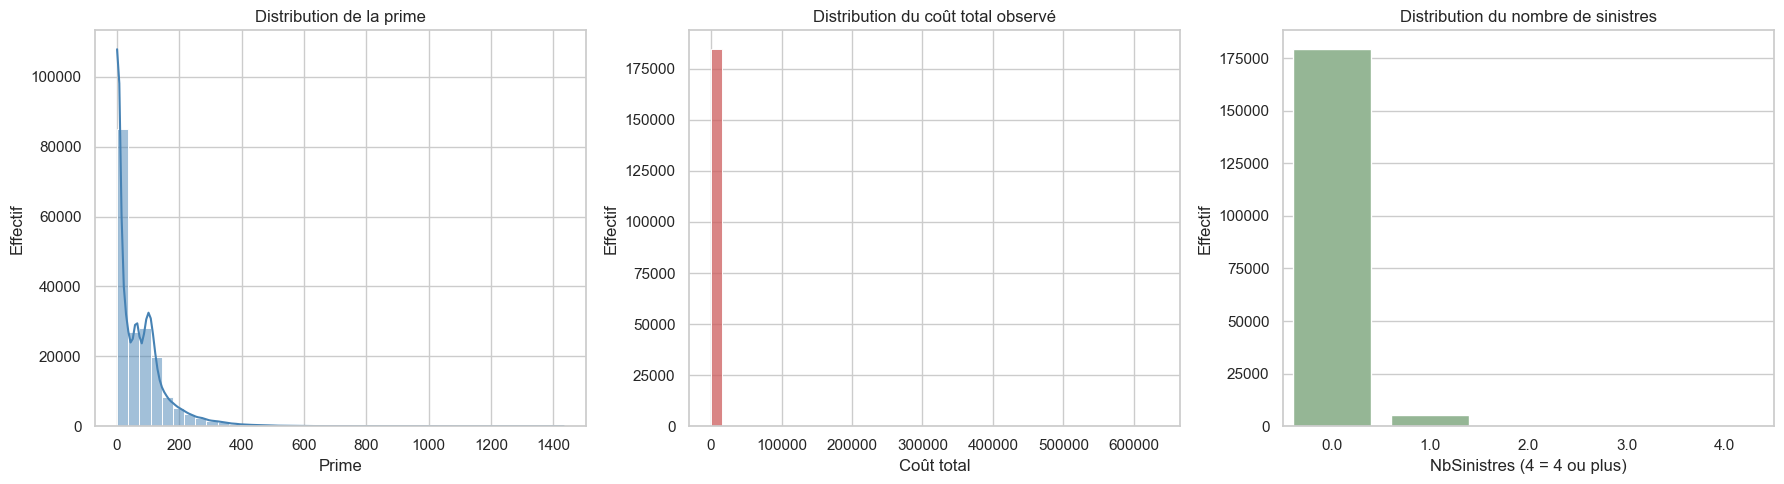

In [ ]:
# Vue d'ensemble des trois variables quantitatives les plus importantes de l'EDA.
# On crée une figure avec 3 graphiques côte à côte (1 ligne, 3 colonnes).
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# histogramme des primes
sns.histplot(fremotor['Premium'].dropna(), bins=40, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution de la prime')
axes[0].set_xlabel('Prime')
axes[0].set_ylabel('Effectif')

# histogramme des cout
sns.histplot(fremotor['Cout'].dropna(), bins=40, color='indianred', ax=axes[1])
axes[1].set_title('Distribution du coût total observé')
axes[1].set_xlabel('Coût total')
axes[1].set_ylabel('Effectif')

# Regroupement de la queue supérieure pour garder une lecture simple du nombre de sinistres.
nbsin_plot = fremotor['NbSinistres'].fillna(0)
nbsin_plot = nbsin_plot.where(nbsin_plot <= 3, 4)
ordre = sorted(nbsin_plot.unique())
sns.countplot(x=nbsin_plot, order=ordre, color='darkseagreen', ax=axes[2])
axes[2].set_title('Distribution du nombre de sinistres')
axes[2].set_xlabel('NbSinistres (4 = 4 ou plus)')
axes[2].set_ylabel('Effectif')

plt.tight_layout()
plt.show()

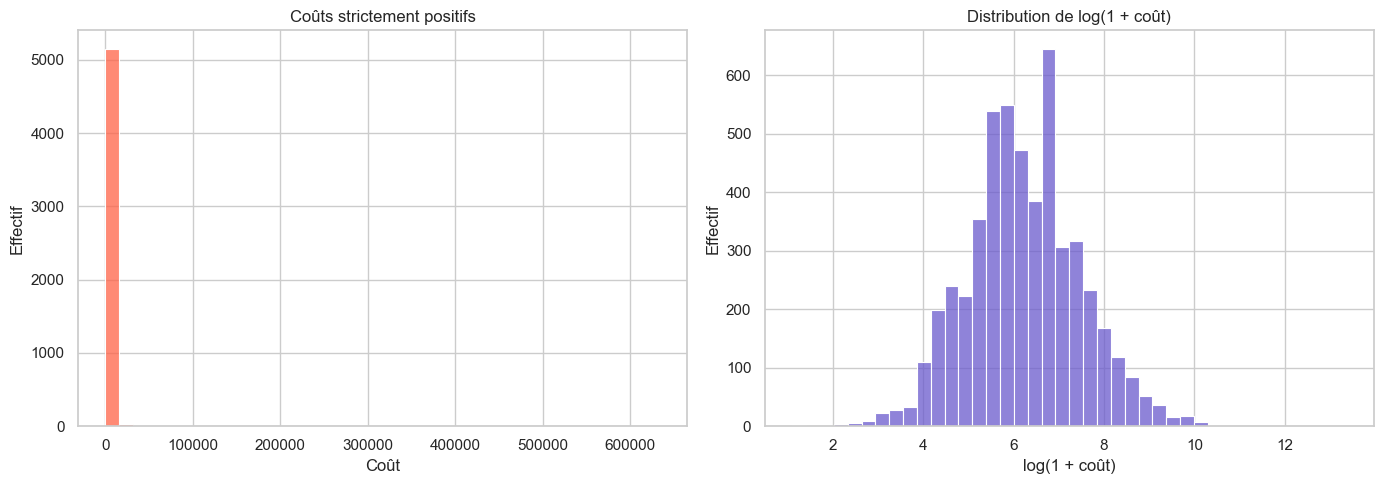

In [ ]:
# Lecture complémentaire sur les montants strictement positifs pour éviter que la masse en zéro n'écrase la distribution.
cout_positif = fremotor.loc[fremotor['Cout'] > 0, 'Cout']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(cout_positif, bins=40, color='tomato', ax=axes[0])
axes[0].set_title('Coûts strictement positifs')
axes[0].set_xlabel('Coût')
axes[0].set_ylabel('Effectif')

# La transformation logarithmique améliore fortement la lecture de l'asymétrie des coûts.
sns.histplot(np.log1p(cout_positif), bins=40, color='slateblue', ax=axes[1])
axes[1].set_title('Distribution de log(1 + coût)')
axes[1].set_xlabel('log(1 + coût)')
axes[1].set_ylabel('Effectif')

plt.tight_layout()
plt.show()

La distribution de la **prime** apparaît fortement asymétrique à droite : une grande partie des contrats se concentre sur des montants relativement faibles, tandis qu'une minorité d'observations présente des primes nettement plus élevées. Cette structure est classique en assurance automobile et traduit l'existence de profils plus chargés ou de garanties plus couvrantes.

La variable **Cout** présente une asymétrie encore plus marquée. La masse principale des observations est située à zéro, ce qui reflète la rareté des sinistres sur le portefeuille. Parmi les coûts strictement positifs, la distribution reste très étalée avec une longue queue à droite. La représentation en échelle logarithmique montre que les sinistres positifs se répartissent sur plusieurs ordres de grandeur, ce qui confirme l'hétérogénéité importante des montants.

Enfin, la variable **NbSinistres** est extrêmement concentrée sur la modalité zéro, avec une très faible proportion de lignes comportant un, deux ou plusieurs sinistres. Cette distribution justifie pleinement le recours à des modèles spécifiques aux données de comptage et souligne le caractère déséquilibré du problème de prédiction.

Dans l'ensemble, ces trois distributions mettent en évidence une base très asymétrique, peu sinistrée et fortement concentrée, ce qui conforte les choix de modélisation retenus par la suite : régression logistique pour la survenue d'un sinistre, Poisson pour la fréquence et Gamma ou Tweedie pour les coûts.

#### 3. Analyse par garantie

In [ ]:

# construction de tableau d'analyse avec groupby
analyse_garantie = (
    fremotor
    .groupby('Guarantee')
    .agg(
        Nb_lignes=('IDpol', 'count'),
        Prime_moyenne=('Premium', 'mean'),
        Prime_totale=('Premium', 'sum'),
        NbSinistres_total=('NbSinistres', 'sum'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Cout_total=('Cout', 'sum'),
        Cout_moyen=('Cout', 'mean')
    )
    .sort_values('Cout_total', ascending=False)
)

analyse_garantie


,Nb_lignes,Prime_moyenne,Prime_totale,NbSinistres_total,Frequence_moyenne,Cout_total,Cout_moyen
Guarantee,,,,,,,
RC,30765,172.599158,5310013.1,2558.0,0.083146,4136221.0,134.445669
Dom. tous acc.,30765,80.500341,2476593.0,542.0,0.017617,946155.0,30.754266
Vol,30765,44.860978,1380148.0,354.0,0.011507,719532.0,23.388006
BdG,30765,24.903624,766160.0,1925.0,0.062571,521105.0,16.938242
Incendie,30765,4.224606,129970.0,53.0,0.001723,137363.0,4.464911
Autres,30765,91.068454,2801721.0,125.0,0.004063,96899.0,3.149651


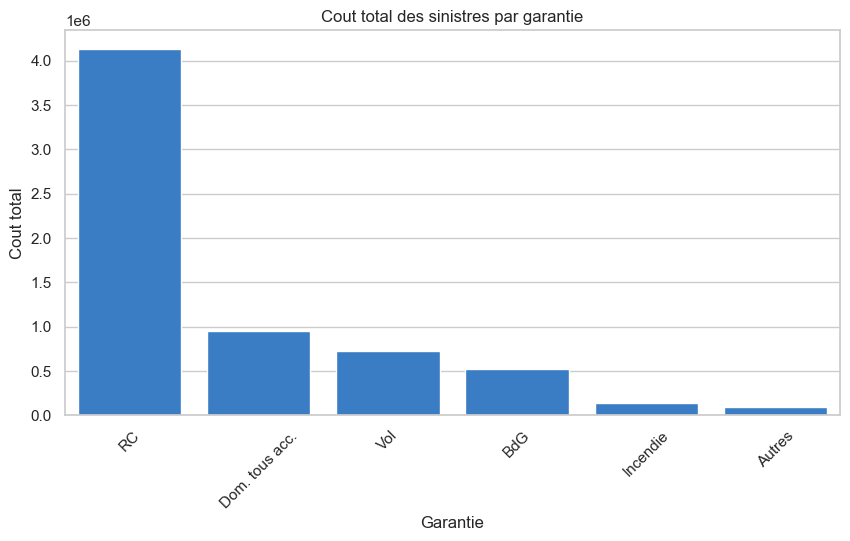

In [731]:
# visualisation avec barplot 
plt.figure(figsize=(10, 5))
sns.barplot(data=analyse_garantie.reset_index(), x='Guarantee', y='Cout_total', color='#237CDB')
plt.title("Cout total des sinistres par garantie")
plt.xlabel("Garantie")
plt.ylabel("Cout total")
plt.xticks(rotation=45)
plt.show()


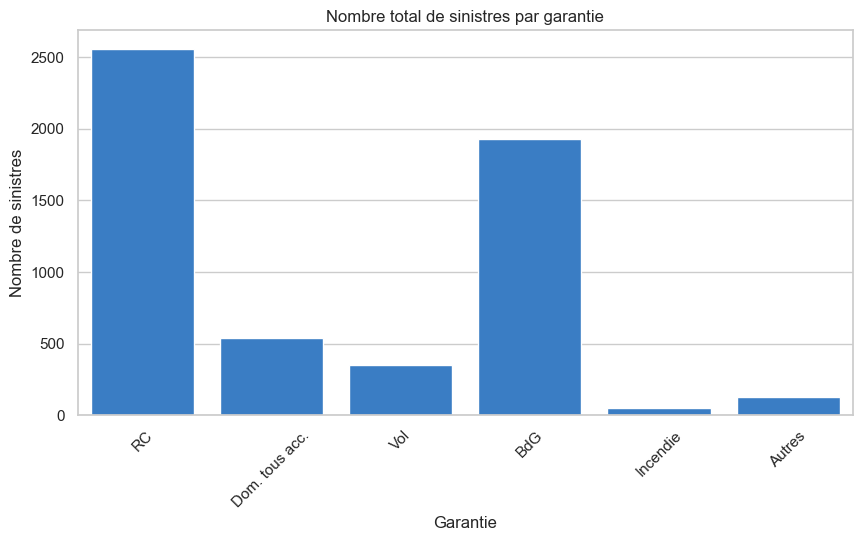

In [48]:
plt.figure(figsize=(10, 5))
sns.barplot(data=analyse_garantie.reset_index(), x='Guarantee', y='NbSinistres_total',color='#237CDB')
plt.title("Nombre total de sinistres par garantie")
plt.xlabel("Garantie")
plt.ylabel("Nombre de sinistres")
plt.xticks(rotation=45)
plt.show()


L’analyse par garantie met en évidence des différences marquées entre la fréquence des sinistres et leur coût total. La garantie de **responsabilité civile (RC)** apparaît comme la plus importante du portefeuille, à la fois en nombre de sinistres et en coût total. Elle concentre donc une part majeure de la charge globale de sinistralité.

La garantie **bris de glace (BdG)** se distingue également par un nombre élevé de sinistres, mais son coût total reste nettement plus faible que celui de la responsabilité civile. Cela suggère des sinistres relativement fréquents mais de sévérité plus modérée. À l’inverse, les garanties **dommages tous accidents** et **vol** présentent un nombre de sinistres plus limité, tout en générant des coûts totaux significatifs, ce qui peut traduire des sinistres moins fréquents mais plus coûteux en moyenne.

Enfin, les garanties **incendie** et **autres** occupent une place plus marginale dans le portefeuille, tant en fréquence qu’en coût total. Globalement, cette analyse montre que toutes les garanties ne contribuent pas de la même manière au risque : certaines pèsent surtout par leur fréquence, d’autres par leur sévérité. Cette distinction est essentielle pour orienter l’analyse actuarielle et la tarification.

Ainsi, la sinistralité du portefeuille ne doit pas être analysée uniquement en volume de sinistres, mais aussi en intensité financière, car les garanties les plus fréquentes ne sont pas nécessairement les plus coûteuses en moyenne.


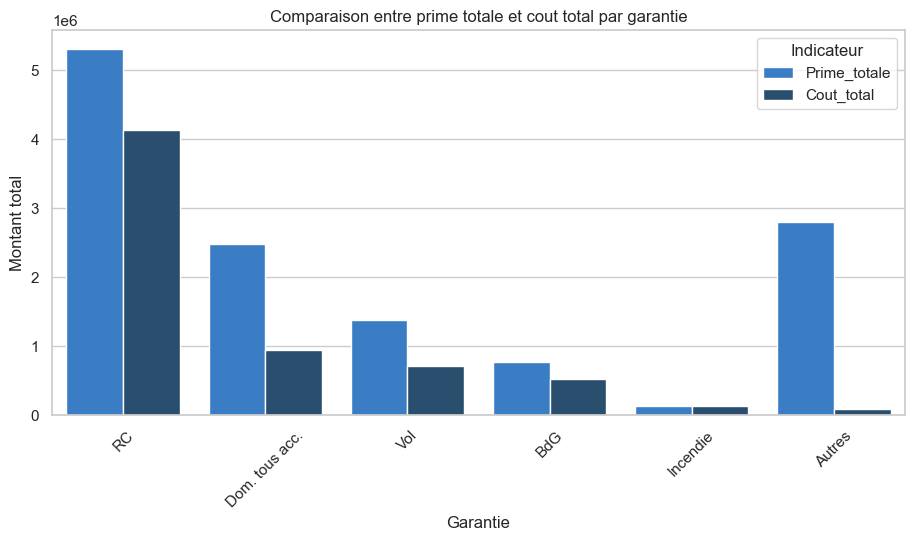

In [49]:
comparaison_garantie = analyse_garantie.reset_index()[['Guarantee', 'Prime_totale', 'Cout_total']]

comparaison_long = comparaison_garantie.melt(
    id_vars='Guarantee',
    value_vars=['Prime_totale', 'Cout_total'],
    var_name='Indicateur',
    value_name='Valeur'
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=comparaison_long,
    x='Guarantee',
    y='Valeur',
    hue='Indicateur',
    palette={'Prime_totale': '#237CDB', 'Cout_total': '#1f4e79'}
)
plt.title("Comparaison entre prime totale et cout total par garantie")
plt.xlabel("Garantie")
plt.ylabel("Montant total")
plt.xticks(rotation=45)
plt.legend(title="Indicateur")
plt.show()


La comparaison croisée entre les primes totales et les coûts totaux des sinistres par garantie met en évidence des situations contrastées selon les couvertures. La garantie de **responsabilité civile (RC)** occupe une place centrale dans le portefeuille : elle est à la fois celle qui génère le plus de primes et celle qui supporte le coût total de sinistres le plus élevé. Cela confirme son poids majeur dans l’équilibre technique global du portefeuille.

Les garanties **dommages tous accidents**, **vol** et **bris de glace** présentent également une structure globalement cohérente : les primes encaissées y restent supérieures aux coûts observés, tout en montrant une charge de sinistralité non négligeable. Elles participent donc de manière importante au risque, mais sans atteindre le niveau de la responsabilité civile.

La garantie **incendie** apparaît plus marginale, avec des montants de primes et de coûts relativement faibles. À l’inverse, la garantie **autres** se distingue par une situation particulière : elle génère un volume de primes élevé alors que le coût total des sinistres associé reste relativement faible. Cela peut s’expliquer par le fait que cette catégorie regroupe plusieurs garanties hétérogènes, dont certaines produisent des primes sans donner lieu à une charge sinistre importante sur la période étudiée.

Globalement, ce graphique suggère que l’équilibre entre prime et sinistralité varie fortement selon les garanties. Certaines, comme la responsabilité civile, concentrent à la fois les encaissements et les risques, tandis que d’autres semblent beaucoup moins contributives à la charge globale.


#### 5. Analyse selon le profil du conducteur

### Par sexe

In [50]:
analyse_genre = (
    fremotor
    .groupby('DrivGender')
    .agg(
        Prime_moyenne=('Premium', 'mean'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Cout_moyen=('Cout', 'mean'),
        Taux_sinistre=('Sinistre', 'mean')
    )
)

analyse_genre


,Prime_moyenne,Frequence_moyenne,Cout_moyen,Taux_sinistre
DrivGender,,,,
Femme,64.402180,0.029177,28.401607,0.028076
Homme,72.474777,0.030592,39.268231,0.029476


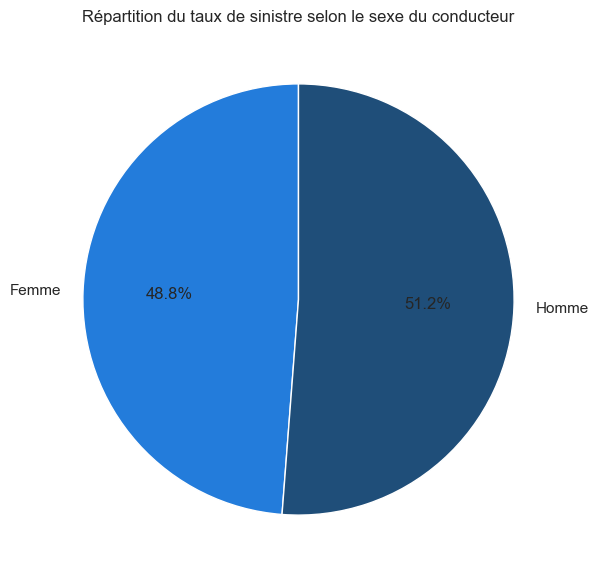

In [51]:
plt.figure(figsize=(7, 7))

plt.pie(
    analyse_genre['Taux_sinistre'],
    labels=analyse_genre.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#237CDB', '#1f4e79']
)

plt.title("Répartition du taux de sinistre selon le sexe du conducteur")
plt.show()


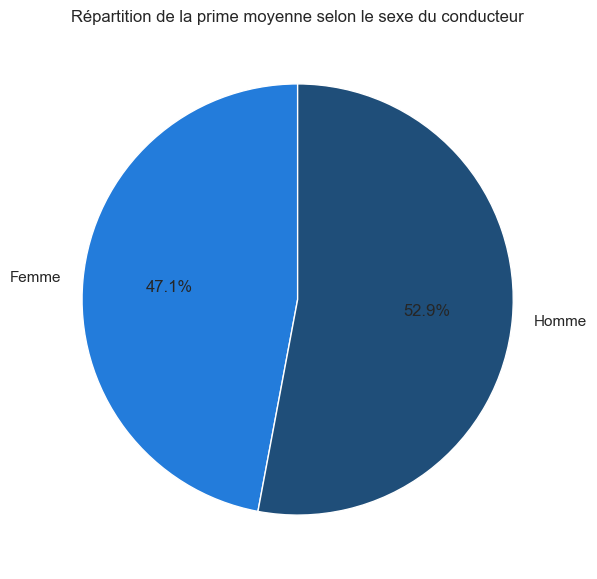

In [52]:
plt.figure(figsize=(7, 7))

plt.pie(
    analyse_genre['Prime_moyenne'],
    labels=analyse_genre.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#237CDB', '#1f4e79']
)

plt.title("Répartition de la prime moyenne selon le sexe du conducteur")
plt.show()



Les hommes présentent un taux de sinistre légèrement supérieur à celui des femmes, ainsi qu’une prime moyenne plus élevée. Cela suggère une cohérence globale entre le risque observé et la tarification, même si les écarts restent modérés.

### Par age du conducteur

In [ ]:
# transformation de la variable age en variable catégorielle, on choisit segmente selon jeune, ....
fremotor['ClasseAgeConducteur'] = pd.cut(
    fremotor['DrivAge'],
    bins=[17, 25, 35, 50, 65, 100],
    labels=['18-25', '26-35', '36-50', '51-65', '66+']
)

# tableau d'analyse avec les clesses d'age en ligne et les statistiques en colonnes
analyse_age = (
    fremotor
    .groupby('ClasseAgeConducteur', observed=False)
    .agg(
        Prime_moyenne=('Premium', 'mean'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Cout_moyen=('Cout', 'mean'),
        Taux_sinistre=('Sinistre', 'mean')
    )
    .reset_index()
)

analyse_age


,ClasseAgeConducteur,Prime_moyenne,Frequence_moyenne,Cout_moyen,Taux_sinistre
0,18-25,91.640389,0.030033,35.526719,0.028859
1,26-35,73.811719,0.029427,29.720361,0.028410
2,36-50,64.283897,0.031279,32.251427,0.030129
3,51-65,63.996280,0.028883,60.795071,0.027667
4,66+,61.505748,0.028893,31.638990,0.027828


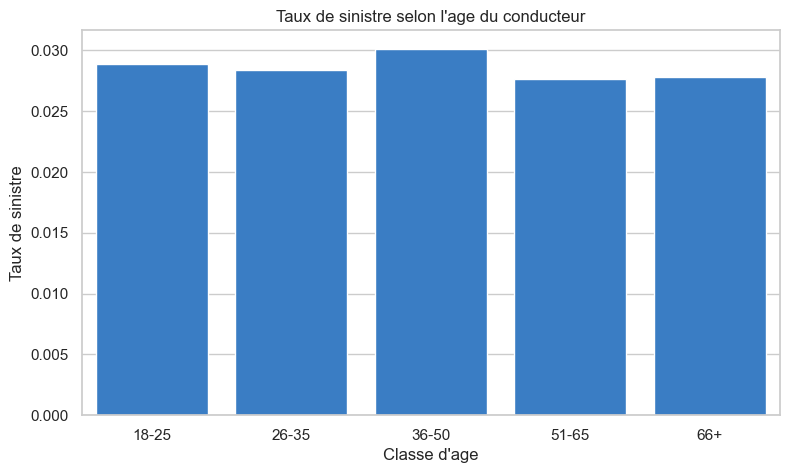

In [54]:
plt.figure(figsize=(9, 5))
sns.barplot(data=analyse_age, x='ClasseAgeConducteur', y='Taux_sinistre', color='#237CDB')
plt.title("Taux de sinistre selon l'age du conducteur")
plt.xlabel("Classe d'age")
plt.ylabel("Taux de sinistre")
plt.show()



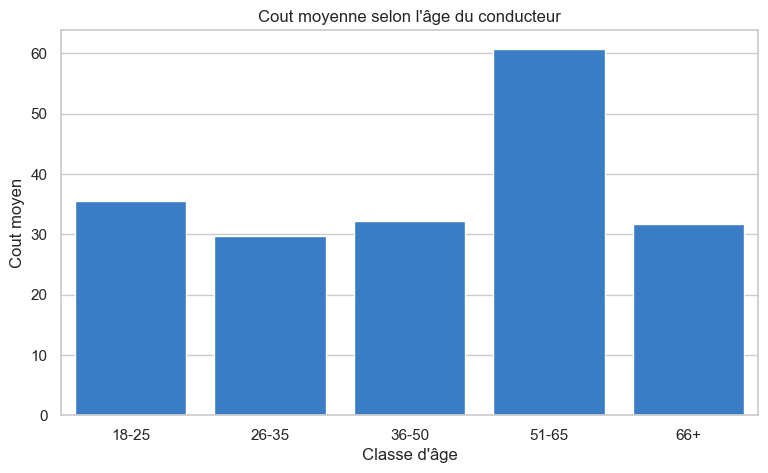

In [732]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=analyse_age,
    x='ClasseAgeConducteur',
    y='Cout_moyen',
    color='#237CDB'
)
plt.title("Cout moyenne selon l'âge du conducteur")
plt.xlabel("Classe d'âge")
plt.ylabel("Cout moyen")
plt.show()


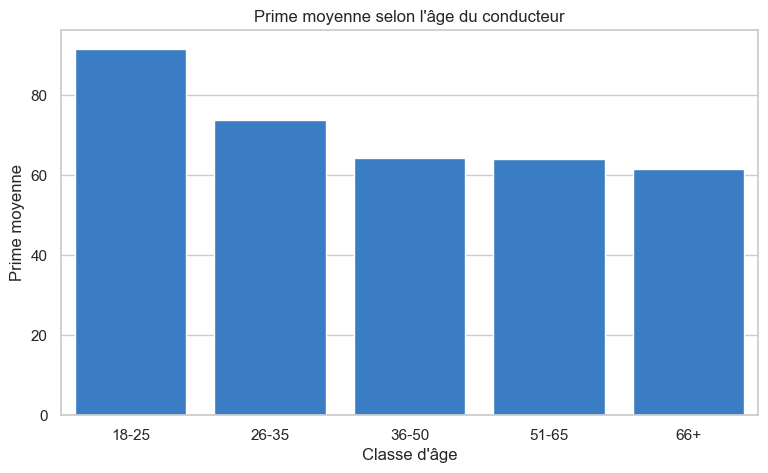

In [56]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=analyse_age,
    x='ClasseAgeConducteur',
    y='Prime_moyenne',
    color='#237CDB'
)
plt.title("Prime moyenne selon l'âge du conducteur")
plt.xlabel("Classe d'âge")
plt.ylabel("Prime moyenne")
plt.show()


L’analyse croisée du taux de sinistre et de la prime moyenne selon l’âge du conducteur met en évidence une relation partiellement cohérente entre risque et tarification. Les conducteurs âgés de 18 à 25 ans supportent la prime moyenne la plus élevée du portefeuille, ce qui traduit vraisemblablement une anticipation d’un risque plus important par l’assureur. Pourtant, dans les données observées, ce ne sont pas eux qui présentent le taux de sinistre le plus élevé : la classe 36-50 ans apparaît légèrement plus sinistrée.

Par ailleurs, la prime moyenne décroît globalement avec l’âge, avec des niveaux plus faibles pour les classes 36-50 ans, 51-65 ans et 66+. Cela suggère que la tarification dépend non seulement de la sinistralité observée dans cet échantillon, mais aussi d’autres critères actuariels ou commerciaux non directement visibles dans cette analyse descriptive.

Ainsi, l’âge du conducteur semble bien jouer un rôle dans la structure des primes, mais le lien entre prime et sinistralité n’est pas parfaitement linéaire dans les données étudiées.

### 6. Analyse selon le vehicule

In [57]:
analyse_usage = (
    fremotor
    .groupby('VehUsage')
    .agg(
        Prime_moyenne=('Premium', 'mean'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Cout_moyen=('Cout', 'mean'),
        Taux_sinistre=('Sinistre', 'mean')
    )
    .sort_values('Taux_sinistre', ascending=False)
)

analyse_usage


,Prime_moyenne,Frequence_moyenne,Cout_moyen,Taux_sinistre
VehUsage,,,,
Tournees pro,96.503727,0.042897,39.401547,0.042194
Professionnel,85.510901,0.040534,58.157351,0.038771
Prive-trajet travail,69.129487,0.029772,34.990988,0.028673


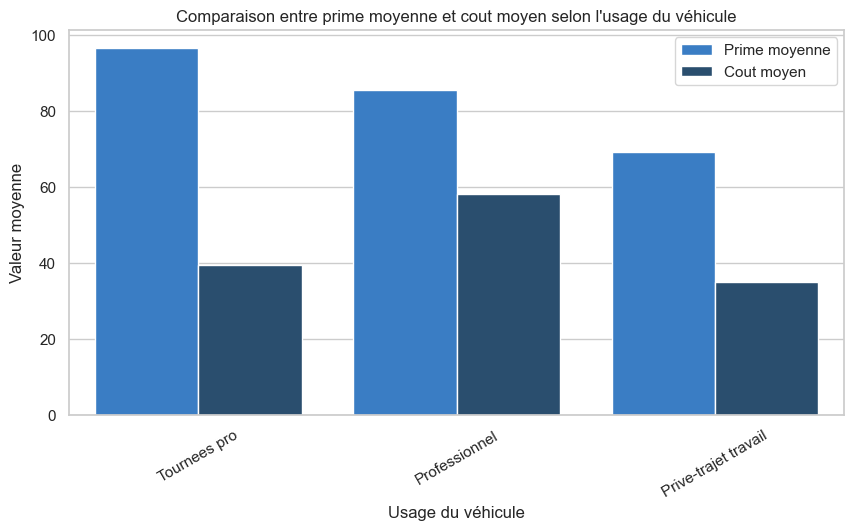

In [58]:
comparaison_usage = analyse_usage.reset_index()[['VehUsage', 'Prime_moyenne', 'Cout_moyen']]

comparaison_usage_long = comparaison_usage.melt(
    id_vars='VehUsage',
    value_vars=['Prime_moyenne', 'Cout_moyen'],
    var_name='Indicateur',
    value_name='Valeur'
)

comparaison_usage_long['Indicateur'] = comparaison_usage_long['Indicateur'].replace({
    'Prime_moyenne': 'Prime moyenne',
    'Cout_moyen': 'Cout moyen'
})

plt.figure(figsize=(10, 5))
sns.barplot(
    data=comparaison_usage_long,
    x='VehUsage',
    y='Valeur',
    hue='Indicateur',
    palette={'Prime moyenne': '#237CDB', 'Cout moyen': '#1f4e79'}
)
plt.title("Comparaison entre prime moyenne et cout moyen selon l'usage du véhicule")
plt.xlabel("Usage du véhicule")
plt.ylabel("Valeur moyenne")
plt.xticks(rotation=30)
plt.legend(title="")
plt.show()


La comparaison entre prime moyenne et coût moyen selon l’usage du véhicule montre des différences nettes entre les catégories. Les véhicules utilisés pour un tourné **professionnel**  présentent la prime moyenne la plus élevée, ce qui indique une tarification plus forte de cet usage. Toutefois, ce n’est pas cette catégorie qui enregistre le coût moyen le plus important.

En effet, la catégorie Professionnelle se distingue par le coût moyen de sinistre le plus élevé, tout en conservant une prime moyenne également importante. Cela suggère que l’usage professionnel constitue un facteur de risque significatif dans le portefeuille. Les véhicules **Privées ou trajet domicile** affichent des niveaux plus faibles de prime moyenne et de coût moyen, ce qui paraît cohérent avec un usage moins intensif ou moins exposé.

Dans l’ensemble, la hiérarchie des primes et des coûts observés confirme que l’usage du véhicule joue un rôle important dans la structure du risque.


In [59]:
fremotor['ClasseAgeVehicule'] = pd.cut(
    fremotor['VehAge'],
    bins=[-1, 2, 5, 10, 20, 100],
    labels=['0-2', '3-5', '6-10', '11-20', '20+']
)

analyse_vehage = (
    fremotor
    .groupby('ClasseAgeVehicule', observed=False)
    .agg(
        Prime_moyenne=('Premium', 'mean'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Cout_moyen=('Cout', 'mean'),
        Taux_sinistre=('Sinistre', 'mean')
    )
    .reset_index()
)

analyse_vehage


,ClasseAgeVehicule,Prime_moyenne,Frequence_moyenne,Cout_moyen,Taux_sinistre
0,0-2,95.943839,0.030782,39.134588,0.029569
1,3-5,86.968067,0.036423,59.716083,0.035260
2,6-10,66.619897,0.031763,30.915949,0.030444
3,11-20,46.552074,0.021732,20.812332,0.021119
4,20+,34.990135,0.014865,16.383333,0.013514


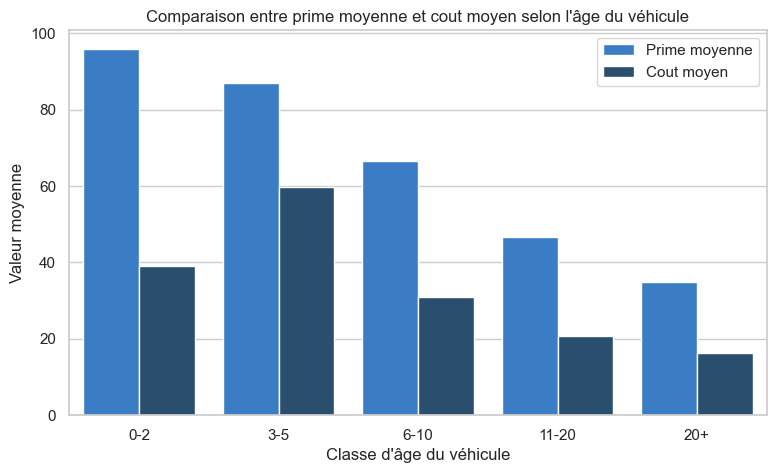

In [60]:
comparaison_vehage = analyse_vehage[['ClasseAgeVehicule', 'Prime_moyenne', 'Cout_moyen']]

comparaison_vehage_long = comparaison_vehage.melt(
    id_vars='ClasseAgeVehicule',
    value_vars=['Prime_moyenne', 'Cout_moyen'],
    var_name='Indicateur',
    value_name='Valeur'
)

comparaison_vehage_long['Indicateur'] = comparaison_vehage_long['Indicateur'].replace({
    'Prime_moyenne': 'Prime moyenne',
    'Cout_moyen': 'Cout moyen'
})

plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparaison_vehage_long,
    x='ClasseAgeVehicule',
    y='Valeur',
    hue='Indicateur',
    palette={'Prime moyenne': '#237CDB', 'Cout moyen': '#1f4e79'}
)
plt.title("Comparaison entre prime moyenne et cout moyen selon l'âge du véhicule")
plt.xlabel("Classe d'âge du véhicule")
plt.ylabel("Valeur moyenne")
plt.legend(title="")
plt.show()


L’analyse croisée entre la prime moyenne et le coût moyen selon l’âge du véhicule met en évidence une décroissance globale des deux indicateurs avec l’ancienneté du véhicule. Les véhicules les plus récents (`0-2 ans`) présentent les primes moyennes les plus élevées, ce qui est cohérent avec une valeur assurée plus importante et un coût potentiel de réparation plus élevé.

La classe `3-5 ans` se distingue par le coût moyen le plus élevé, supérieur à celui des véhicules très récents. Cela peut suggérer que cette catégorie combine encore une valeur importante avec une exposition au risque plus marquée. À partir de `6 ans` et plus, primes et coûts moyens diminuent progressivement, ce qui traduit une moindre valorisation assurantielle et probablement une couverture plus limitée.

Globalement, ces résultats suggèrent une cohérence entre la tarification et le niveau de coût observé : les véhicules les plus récents ou intermédiaires sont ceux qui concentrent les montants moyens les plus élevés.


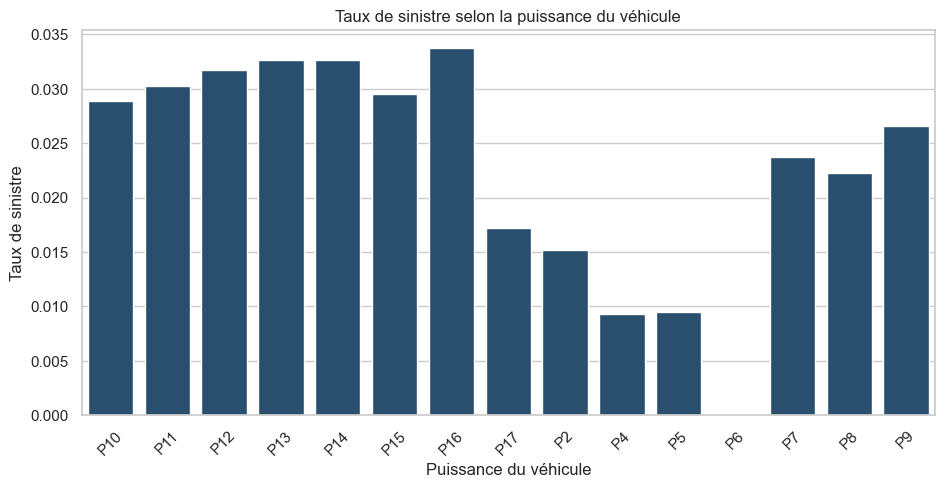

In [61]:
analyse_power = (
    fremotor
    .groupby('VehPower')
    .agg(
        Prime_moyenne=('Premium', 'mean'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Cout_moyen=('Cout', 'mean'),
        Taux_sinistre=('Sinistre', 'mean')
    )
    .reset_index()
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=analyse_power,
    x='VehPower',
    y='Taux_sinistre',
    color='#1f4e79'
)
plt.title("Taux de sinistre selon la puissance du véhicule")
plt.xlabel("Puissance du véhicule")
plt.ylabel("Taux de sinistre")
plt.xticks(rotation=45)
plt.show()


L’analyse du taux de sinistre selon la puissance du véhicule met en évidence des écarts notables entre les différentes classes de `VehPower`. Rappelons que cette variable classe les véhicules des moins puissants (`P2`) aux plus puissants (`P15`). On observe que plusieurs classes situées parmi les puissances intermédiaires et élevées, notamment autour de `P10` à `P15`, présentent des taux de sinistre relativement plus élevés que les classes les moins puissantes.

Ce résultat peut s’interpréter de plusieurs façons. Les véhicules plus puissants peuvent être associés à des usages plus intensifs, à des profils de conducteurs différents ou à des conditions de circulation particulières, ce qui peut contribuer à accroître l’exposition au risque. Toutefois, la relation n’apparaît pas parfaitement monotone : toutes les classes de forte puissance ne présentent pas exactement le même niveau de sinistralité, ce qui suggère que la puissance n’agit pas seule mais en interaction avec d’autres caractéristiques du véhicule et du conducteur.

Par ailleurs, certaines modalités de `VehPower` sont peu représentées dans la base. Les taux observés pour ces classes doivent donc être interprétés avec prudence, car ils peuvent être sensibles à un faible nombre d’observations. Ainsi, même si l’analyse descriptive suggère que la puissance du véhicule constitue un facteur potentiellement explicatif de la sinistralité, seule la modélisation permettra de confirmer son effet propre une fois les autres variables prises en compte.



In [62]:
analyse_gas = (
    fremotor
    .groupby('VehGas')
    .agg(
        Nombre_obs=('IDpol', 'count'),
        Prime_moyenne=('Premium', 'mean'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Cout_moyen=('Cout', 'mean'),
        Taux_sinistre=('Sinistre', 'mean')
    )
    .sort_values('Taux_sinistre', ascending=False)
)

analyse_gas['Prime_moyenne'] = analyse_gas['Prime_moyenne'].round(2)
analyse_gas['Frequence_moyenne'] = analyse_gas['Frequence_moyenne'].round(4)
analyse_gas['Cout_moyen'] = analyse_gas['Cout_moyen'].round(2)
analyse_gas['Taux_sinistre'] = analyse_gas['Taux_sinistre'].round(4)

analyse_gas


,Nombre_obs,Prime_moyenne,Frequence_moyenne,Cout_moyen,Taux_sinistre
VehGas,,,,,
Diesel,71352,79.40,0.0343,45.69,0.0331
Essence,113238,63.57,0.0274,29.11,0.0264


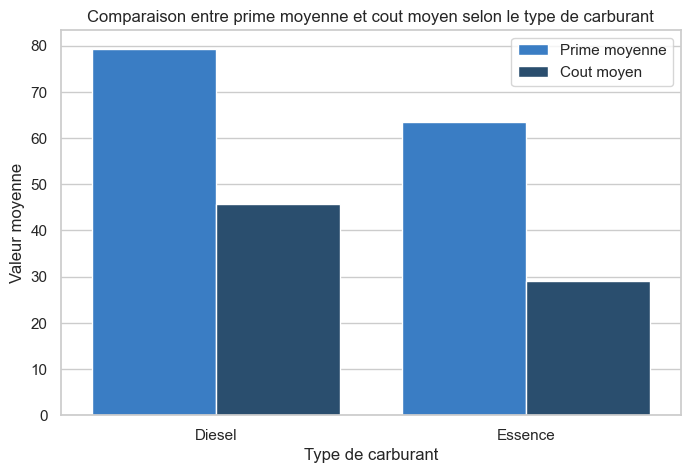

In [63]:
comparaison_gas = analyse_gas.reset_index()[['VehGas', 'Prime_moyenne', 'Cout_moyen']]

comparaison_gas_long = comparaison_gas.melt(
    id_vars='VehGas',
    value_vars=['Prime_moyenne', 'Cout_moyen'],
    var_name='Indicateur',
    value_name='Valeur'
)

comparaison_gas_long['Indicateur'] = comparaison_gas_long['Indicateur'].replace({
    'Prime_moyenne': 'Prime moyenne',
    'Cout_moyen': 'Cout moyen'
})

plt.figure(figsize=(8, 5))
sns.barplot(
    data=comparaison_gas_long,
    x='VehGas',
    y='Valeur',
    hue='Indicateur',
    palette={'Prime moyenne': '#237CDB', 'Cout moyen': '#1f4e79'}
)
plt.title("Comparaison entre prime moyenne et cout moyen selon le type de carburant")
plt.xlabel("Type de carburant")
plt.ylabel("Valeur moyenne")
plt.legend(title="")
plt.show()


L’analyse selon le type de carburant montre que les véhicules **diesel** présentent à la fois une prime moyenne plus élevée et un coût moyen de sinistre plus important que les véhicules **essence**. Cette double différence suggère une cohérence globale entre le risque observé et la tarification appliquée.

Les véhicules diesel semblent donc davantage exposés, ou associés à des profils d’usage plus risqués, ce qui peut expliquer des primes plus élevées. À l’inverse, les véhicules essence apparaissent moins coûteux en moyenne pour l’assureur et supportent également une prime moyenne plus faible.

Ainsi, le type de carburant semble être un facteur différenciant dans le portefeuille, tant du point de vue de la sinistralité que de la tarification.


### 7. Analyse selon la région

La variable `Region` permet d'étudier la dimension géographique du portefeuille à partir d'un découpage plus lisible que l'ancienne variable `Area`. L'enjeu est ici de comparer les niveaux de prime moyenne, de fréquence moyenne et de coût moyen observé selon les grands territoires du portefeuille.

In [64]:
# Tableau de synthèse régional : effectif, prime, fréquence, taux de sinistre et coût moyen.
analyse_region = (
    fremotor.groupby('Region')
    .agg(
        Effectif=('IDpol', 'count'),
        Prime_moyenne=('Premium', 'mean'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Taux_sinistre=('Sinistre', 'mean'),
        Cout_moyen=('Cout', 'mean')
    )
    .reset_index()
    .sort_values('Effectif', ascending=False)
)

analyse_region

,Region,Effectif,Prime_moyenne,Frequence_moyenne,Taux_sinistre,Cout_moyen
1,Centre,96264,64.629772,0.027913,0.026895,28.506389
0,Autre,36426,75.352841,0.032724,0.031543,54.295942
2,Region parisienne,27804,79.664034,0.032441,0.030859,32.059848
3,Sud-Ouest,24096,69.858205,0.032205,0.031375,39.174967


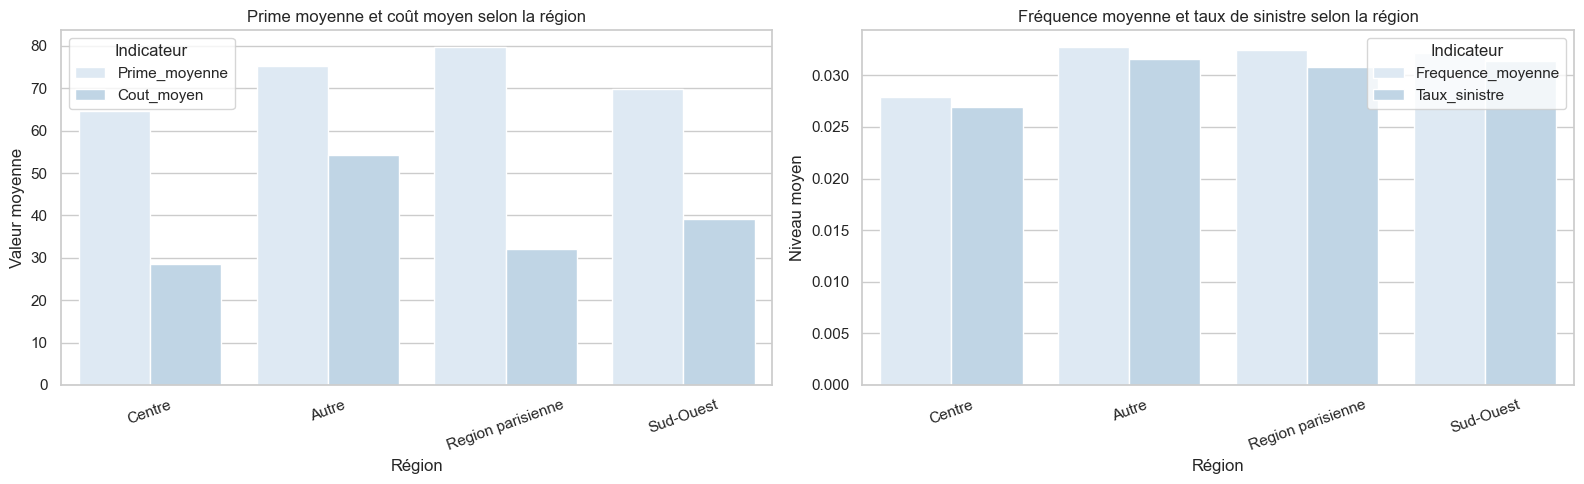

In [65]:
# Comparaison régionale sur les niveaux moyens de prime, coût, fréquence et sinistralité.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

comparaison_region = analyse_region.melt(
    id_vars='Region',
    value_vars=['Prime_moyenne', 'Cout_moyen'],
    var_name='Indicateur',
    value_name='Valeur'
)

sns.barplot(data=comparaison_region, x='Region', y='Valeur', hue='Indicateur', ax=axes[0])
axes[0].set_title('Prime moyenne et coût moyen selon la région')
axes[0].set_xlabel('Région')
axes[0].set_ylabel('Valeur moyenne')
axes[0].tick_params(axis='x', rotation=20)

comparaison_freq_region = analyse_region.melt(
    id_vars='Region',
    value_vars=['Frequence_moyenne', 'Taux_sinistre'],
    var_name='Indicateur',
    value_name='Valeur'
)

sns.barplot(data=comparaison_freq_region, x='Region', y='Valeur', hue='Indicateur', ax=axes[1])
axes[1].set_title('Fréquence moyenne et taux de sinistre selon la région')
axes[1].set_xlabel('Région')
axes[1].set_ylabel('Niveau moyen')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

L'analyse régionale met en évidence des écarts de niveau entre territoires, aussi bien sur la prime moyenne que sur les indicateurs de sinistralité. Comme les effectifs sont suffisants dans chacune des quatre grandes régions, ces différences apparaissent économiquement interprétables et ne semblent pas résulter d'un simple bruit d'échantillonnage.

La variable `Region` est ainsi particulièrement intéressante pour l'analyse descriptive, car elle permet une lecture géographique immédiate du portefeuille. Elle constitue aussi une variable plus simple à commenter  que `Area`, dont la signification restait moins claire.

### 7.1 Analyse croisée région x garantie

Au-delà des moyennes régionales globales, il est utile d'étudier comment la géographie interagit avec le type de garantie. Ce croisement permet d'identifier d'éventuelles zones où certaines garanties apparaissent plus coûteuses, plus fréquentes ou plus fortement tarifées que d'autres.

In [66]:
# Croisement détaillé entre la région et la garantie pour étudier l'hétérogénéité du portefeuille.
analyse_region_garantie = (
    fremotor.groupby(['Region', 'Guarantee'])
    .agg(
        Effectif=('IDpol', 'count'),
        Prime_moyenne=('Premium', 'mean'),
        Frequence_moyenne=('NbSinistres', 'mean'),
        Cout_moyen=('Cout', 'mean')
    )
    .reset_index()
)

analyse_region_garantie.head(12)

,Region,Guarantee,Effectif,Prime_moyenne,Frequence_moyenne,Cout_moyen
0,Autre,Autres,6071,90.147422,0.002965,3.463515
1,Autre,BdG,6071,28.007577,0.067534,19.318399
2,Autre,Dom. tous acc.,6071,99.892439,0.021578,39.840883
3,Autre,Incendie,6071,4.994564,0.002471,9.285785
4,Autre,RC,6071,175.325745,0.089112,219.724592
5,Autre,Vol,6071,53.749300,0.012683,34.142481
6,Centre,Autres,16044,87.434680,0.003553,2.446958
7,Centre,BdG,16044,23.642670,0.063077,16.307280
8,Centre,Dom. tous acc.,16044,73.052730,0.016642,29.478621
9,Centre,Incendie,16044,3.662615,0.001496,3.132947


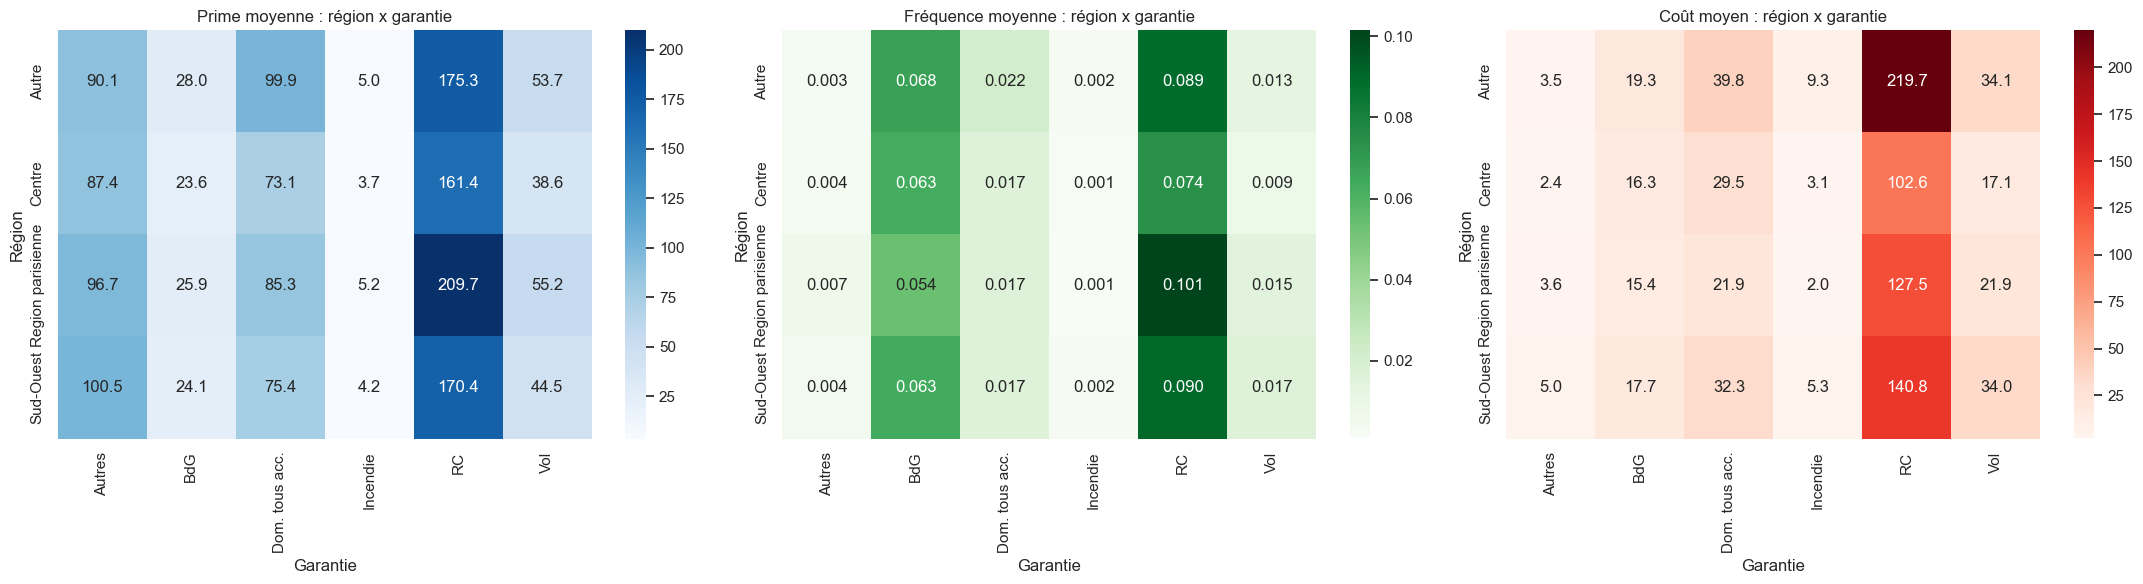

In [67]:
# Heatmaps pour visualiser les différences de niveau selon le couple région x garantie.
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

pivot_prime = analyse_region_garantie.pivot(index='Region', columns='Guarantee', values='Prime_moyenne')
pivot_freq = analyse_region_garantie.pivot(index='Region', columns='Guarantee', values='Frequence_moyenne')
pivot_cout = analyse_region_garantie.pivot(index='Region', columns='Guarantee', values='Cout_moyen')

sns.heatmap(pivot_prime, annot=True, fmt='.1f', cmap='Blues', ax=axes[0])
axes[0].set_title('Prime moyenne : région x garantie')
axes[0].set_xlabel('Garantie')
axes[0].set_ylabel('Région')

sns.heatmap(pivot_freq, annot=True, fmt='.3f', cmap='Greens', ax=axes[1])
axes[1].set_title('Fréquence moyenne : région x garantie')
axes[1].set_xlabel('Garantie')
axes[1].set_ylabel('Région')

sns.heatmap(pivot_cout, annot=True, fmt='.1f', cmap='Reds', ax=axes[2])
axes[2].set_title('Coût moyen : région x garantie')
axes[2].set_xlabel('Garantie')
axes[2].set_ylabel('Région')

plt.tight_layout()
plt.show()

Le croisement `Region x Guarantee` montre que la géographie n'affecte pas toutes les garanties de manière uniforme. Certaines garanties restent relativement stables d'une région à l'autre, tandis que d'autres présentent des écarts plus visibles en prime moyenne, en fréquence ou en coût moyen.

Cette lecture croisée est utile d'un point de vue métier, car elle permet d'éviter une interprétation trop globale de la variable géographique. Une région peut paraître modérément risquée en moyenne, tout en présentant des spécificités marquées sur certaines garanties comme la **RC**, le **bris de glace** ou les **dommages tous accidents**.

Ainsi, l'analyse croisée renforce l'idée que le risque automobile dépend d'une combinaison de facteurs. La région apporte une information pertinente, mais son effet doit être lu en lien avec la nature de la garantie considérée.

### 8. Etude de corrélation

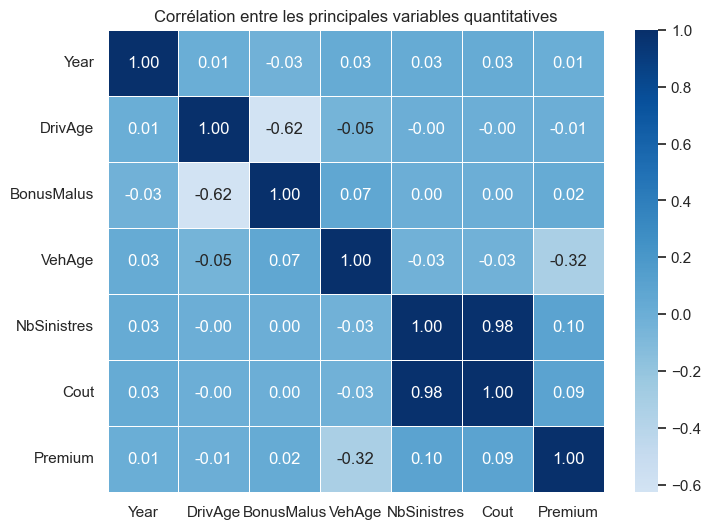

In [68]:
vars_quanti = [
    'Year', 'DrivAge', 'BonusMalus', 'VehAge',
    'NbSinistres', 'Cout', 'Premium'
]

corr_quanti = fremotor[vars_quanti].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_quanti,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    center=0,
    linewidths=0.5
)
plt.title("Corrélation entre les principales variables quantitatives")
plt.show()


La matrice de corrélation montre d’abord une très forte corrélation entre `NbSinistres` et `Cout` (`0,98`), ce qui est logique puisque le coût total dépend fortement du nombre de sinistres. Une corrélation négative marquée apparaît également entre `DrivAge` et `BonusMalus` (`-0,62`), ce qui suggère que les conducteurs plus âgés bénéficient en moyenne d’un bonus-malus plus favorable.

La prime est faiblement corrélée aux autres variables quantitatives, à l’exception d’une corrélation négative modérée avec `VehAge` (`-0,32`), traduisant des primes plus faibles pour les véhicules plus anciens. Dans l’ensemble, les autres corrélations restent faibles, ce qui montre que les liens entre variables quantitatives sont globalement limités lorsqu’on les considère séparément.


## 7. Étude du lien entre prime et sinistralité

Afin d’étudier le lien entre la prime et la sinistralité, nous retenons ici la **corrélation de Spearman**, qui permet de mesurer une relation monotone entre variables sans supposer de lien linéaire strict.

Cette approche est particulièrement adaptée aux données d’assurance, souvent marquées par une forte asymétrie, de nombreux zéros et quelques valeurs extrêmes.


In [69]:
from scipy.stats import pointbiserialr, spearmanr, pearsonr, chi2_contingency

In [70]:
# Niveau ligne de garantie
spear_nb_ligne = spearmanr(fremotor['Premium'], fremotor['NbSinistres'])
spear_cout_ligne = spearmanr(fremotor['Premium'], fremotor['Cout'])

resultats_spearman_ligne = pd.DataFrame({
    'Test': [
        'Spearman Premium vs NbSinistres',
        'Spearman Premium vs Cout'
    ],
    'Statistique': [
        spear_nb_ligne.statistic,
        spear_cout_ligne.statistic
    ],
    'p_value': [
        spear_nb_ligne.pvalue,
        spear_cout_ligne.pvalue
    ]
})

resultats_spearman_ligne['Statistique'] = resultats_spearman_ligne['Statistique'].round(4)
resultats_spearman_ligne['p_value'] = resultats_spearman_ligne['p_value'].apply(lambda x: f"{x:.3e}")

resultats_spearman_ligne


,Test,Statistique,p_value
0,Spearman Premium vs NbSinistres,0.0953,0.000e+00
1,Spearman Premium vs Cout,0.0927,0.000e+00


In [71]:
# Niveau police x année
policy_test = (
    fremotor
    .groupby(['IDpol', 'Year'], as_index=False)
    .agg(
        Premium_totale=('Premium', 'sum'),
        NbSinistres_total=('NbSinistres', 'sum'),
        Cout_total=('Cout', 'sum')
    )
)

spear_nb_policy = spearmanr(policy_test['Premium_totale'], policy_test['NbSinistres_total'])
spear_cout_policy = spearmanr(policy_test['Premium_totale'], policy_test['Cout_total'])

resultats_spearman_policy = pd.DataFrame({
    'Test': [
        'Spearman Prime totale vs NbSinistres total',
        'Spearman Prime totale vs Cout total'
    ],
    'Statistique': [
        spear_nb_policy.statistic,
        spear_cout_policy.statistic
    ],
    'p_value': [
        spear_nb_policy.pvalue,
        spear_cout_policy.pvalue
    ]
})

resultats_spearman_policy['Statistique'] = resultats_spearman_policy['Statistique'].round(4)
resultats_spearman_policy['p_value'] = resultats_spearman_policy['p_value'].apply(lambda x: f"{x:.3e}")

resultats_spearman_policy


,Test,Statistique,p_value
0,Spearman Prime totale vs NbSinistres total,0.0893,1.839e-55
1,Spearman Prime totale vs Cout total,0.0909,2.049e-57


Les corrélations de Spearman mettent en évidence un **lien statistiquement significatif** entre la prime et la sinistralité, aussi bien au niveau de la fréquence qu’au niveau du coût. En effet, les `p-values` sont très faibles dans tous les cas.

Toutefois, les coefficients obtenus restent **faibles en valeur absolue**, ce qui signifie que la relation entre prime et sinistre existe mais demeure modérée. Ce résultat est cohérent en assurance : la prime reflète globalement une partie du risque, sans pour autant expliquer parfaitement le nombre ou le coût des sinistres à l’échelle individuelle.

L’analyse confirme donc une **cohérence globale entre tarification et risque observé**, tout en montrant que cette relation reste partielle et qu’elle dépend d’autres facteurs explicatifs.


# III. Modélisation

L'objectif de cette partie est de prolonger l'analyse descriptive par des **modeles predictifs** qui ont un sens metier dans un contexte d'assurance. Nous allons travailler sur trois niveaux complementaires :

- la **probabilite d'avoir au moins un sinistre** ;
- la **frequence du nombre de sinistres** ;
- la **severite moyenne d'un sinistre**.

Nous en deduirons ensuite une **prime pure predite** et une **prime tarifaire indicative** afin de proposer une premiere approche de tarification.

## 1. Préparation de la base de modélisation

Dans cette partie, nous utilisons la table finale `fremotor` au niveau `(IDpol, Year, Guarantee)`. Pour eviter toute fuite d'information, la variable `Premium` observee n'est **pas utilisee comme variable explicative** dans les modeles de risque : elle sera uniquement mobilisee a la fin pour comparer la tarification existante a la tarification predite.

#### Import des librairies et préparation de la base de modélisation

In [72]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from patsy.builtins import Treatment
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import GammaRegressor, LogisticRegression
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score, confusion_matrix, roc_curve
)

In [73]:
modele_data = fremotor.copy()

# Variable binaire pour la classification : 1 si au moins un sinistre est observe.
modele_data['Sinistre'] = (modele_data['NbSinistres'] > 0).astype(int)

# Severite moyenne par sinistre : utile pour le modele Gamma.
modele_data['Severite_par_sinistre'] = np.where(
    modele_data['Cout'] > 0,
    modele_data['Cout'] / modele_data['NbSinistres'].clip(lower=1),
    np.nan
)

# Variables explicatives retenues pour les modèles.
features_model = [
    'Year', 'DrivAge', 'DrivGender', 'BonusMalus', 'LicenceNb', 'PayFreq',
    'VehAge', 'VehClass', 'VehGas', 'VehUsage', 'Garage',
    'Region', 'Channel', 'Marketing', 'Guarantee'
]

# Variables de base pour les modèles paramétriques.
base_variables = [
    'Year', 'DrivAge', 'BonusMalus', 'LicenceNb', 'VehAge',
    'DrivGender', 'VehGas', 'VehUsage', 'Region', 'Guarantee'
]

# Variables catégorielles.
categorical_vars = ['DrivGender', 'VehGas', 'VehUsage', 'Region', 'Guarantee']

# Modalités de référence pour les variables catégorielles.
reference_levels = {
    'DrivGender': 'Homme',
    'VehGas': 'Essence',
    'VehUsage': 'Prive-trajet travail',
    'Region': 'Centre',
    'Guarantee': 'RC'
}

num_cols = ['Year', 'DrivAge', 'BonusMalus', 'LicenceNb', 'VehAge']
cat_cols = [col for col in features_model if col not in num_cols]


### fonction de traitement ou de transformation des données pour l'entrainement des modèles

In [74]:
# normalisation et encodage
def build_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', Pipeline([
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols)
    ])

# métrique dévaluation des modèles
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

# mettre un c devant pour les variables catégorielles
def set_categorical_levels(train_df, test_df, full_df, cat_vars):
    for var in cat_vars:
        categories = pd.Index(full_df[var].dropna().unique())
        train_df[var] = pd.Categorical(train_df[var], categories=categories)
        test_df[var] = pd.Categorical(test_df[var], categories=categories)
    return train_df, test_df


def term_from_variable(var):
    if var in categorical_vars:
        ref = reference_levels[var]
        return f"C({var}, Treatment(reference={ref!r}))"
    return var

# fonction pour la formule du modèle (les variables en questions)
def build_formula(target, variables):
    terms = [term_from_variable(v) for v in variables]
    return f"{target} ~ " + " + ".join(terms)

# fonction pour identifier les variables qui ont des coeff significatifs
def significant_table(result, alpha=0.05):
    table = pd.DataFrame({
        'Variable': result.params.index,
        'Coefficient': result.params.values,
        'p_value': result.pvalues.values
    })
    table['Significatif_5pct'] = np.where(table['p_value'] < alpha, 'Oui', 'Non')
    return table.sort_values('p_value')

# extraction des variables originales pour les variables catégorielles
def extract_original_variable(term_name):
    if term_name.startswith('C('):
        return term_name.split('(')[1].split(',')[0]
    return term_name

# selection de variables dont les coeffs sont significatifs au seuil donné
def selected_variables_from_result(result, alpha=0.05):
    selected_terms = result.pvalues[
        (result.pvalues < alpha) &
        (~result.pvalues.index.isin(['Intercept', 'const']))
    ].index
    selected_variables = [extract_original_variable(term) for term in selected_terms]
    return list(dict.fromkeys(selected_variables))

# fonction de comparaison des prédiction avec la réalité pour les variables catégorielles
def compare_predictions_by_category(df, category_var, observed_col, predictions):
    table = df[[category_var, observed_col]].copy()
    for pred_name, values in predictions.items():
        table[pred_name] = np.asarray(values)
    table = table.groupby(category_var, as_index=False).mean(numeric_only=True)
    for pred_name in predictions:
        table[f'Ecart_abs_{pred_name}'] = (table[pred_name] - table[observed_col]).abs()
    return table

# fonction d'affichage des formats de sortie de modèles pour les variables cat
def summarize_prediction_gaps(df, category_list, observed_col, predictions):
    rows = []
    for var in category_list:
        table = compare_predictions_by_category(df, var, observed_col, predictions)
        for pred_name in predictions:
            rows.append({
                'Variable': var,
                'Modele': pred_name,
                'Ecart_moyen_absolu': table[f'Ecart_abs_{pred_name}'].mean()
            })
    return pd.DataFrame(rows).sort_values(['Variable', 'Ecart_moyen_absolu'])


### Découpage deu jeu de données

In [75]:
# séparation en entrainement et test
train_idx, test_idx = train_test_split(
    modele_data.index,
    test_size=0.25,
    random_state=42,
    stratify=modele_data['Sinistre']
)

train_data = modele_data.loc[
    train_idx,
    features_model + ['Sinistre', 'NbSinistres', 'Severite_par_sinistre', 'Cout', 'Premium']
].copy()
test_data = modele_data.loc[
    test_idx,
    features_model + ['Sinistre', 'NbSinistres', 'Severite_par_sinistre', 'Cout', 'Premium']
].copy()

train_data, test_data = set_categorical_levels(train_data, test_data, modele_data, categorical_vars)

X_train = train_data[features_model].copy()
X_test = test_data[features_model].copy()

print('Nombre d observations train :', len(train_idx))
print('Nombre d observations test :', len(test_idx))
print('Part de sinistres dans le train :', round(train_data['Sinistre'].mean(), 4))
print('Part de sinistres dans le test :', round(test_data['Sinistre'].mean(), 4))

Nombre d observations train : 138442
Nombre d observations test : 46148
Part de sinistres dans le train : 0.029
Part de sinistres dans le test : 0.029


La proportion de sinistres est identique dans l’échantillon d’apprentissage et dans l’échantillon de test (`2,9 %` dans les deux cas). Cela montre que le découpage des données a bien conservé la structure de la variable cible, ce qui est important pour éviter un déséquilibre artificiel entre les deux sous-échantillons et garantir une évaluation plus fiable des modèles.


## 2. Modele de classification : probabilite d'avoir un sinistre

Nous commencons par une **régression logistique**. On procède en deux temps :

1. estimation d'un **modèle** sur l'échantillon d'apprentissage ;
2. sélection des variables significatives à `5%`, puis estimation d'un **modèle réduit** ;
3. pour la prédiction hors échantillon, on conserve une **version pondérée** de la logistique afin de mieux tenir compte du déséquilibre de la sinistralité.

In [76]:
# 1. Modele logistique complet sur train
formula_logit = build_formula('Sinistre', base_variables)
# ajustement du modèle
logit_model = smf.glm(
    formula=formula_logit,
    data=train_data,
    family=sm.families.Binomial()
).fit()

print(logit_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               Sinistre   No. Observations:               138442
Model:                            GLM   Df Residuals:                   138424
Model Family:                Binomial   Df Model:                           17
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -15842.
Date:                Sat, 30 May 2026   Deviance:                       31684.
Time:                        16:54:08   Pearson chi2:                 1.33e+05
No. Iterations:                     9   Pseudo R-squ. (CS):            0.03304
Covariance Type:            nonrobust                                         
                                                                                coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------

In [77]:
# 2. Tableau des termes significatifs au seuil de 5 %
logit_significatifs = significant_table(logit_model, alpha=0.05)
display(logit_significatifs[logit_significatifs['Significatif_5pct'] == 'Oui'])

var_significatives_logit = selected_variables_from_result(logit_model, alpha=0.05)
print('Variables retenues pour le modele reduit :', var_significatives_logit)

,Variable,Coefficient,p_value,Significatif_5pct
11,"C(Guarantee, Treatment(reference='RC'))[T.Vol]",-2.059743,2.901634e-201,Oui
10,"C(Guarantee, Treatment(reference='RC'))[T.Autres]",-3.103797,2.469991e-178,Oui
8,"C(Guarantee, Treatment(reference='RC'))[T.Dom....",-1.590624,1.770535e-175,Oui
9,"C(Guarantee, Treatment(reference='RC'))[T.Ince...",-3.899336,5.964206e-131,Oui
0,Intercept,-657.486866,3.591656e-23,Oui
13,Year,0.327067,5.022221e-23,Oui
17,VehAge,-0.032927,3.373398e-17,Oui
12,"C(Guarantee, Treatment(reference='RC'))[T.BdG]",-0.272969,1.177244e-13,Oui
2,"C(VehGas, Treatment(reference='Essence'))[T.Di...",0.147786,1.978287e-05,Oui
5,"C(Region, Treatment(reference='Centre'))[T.Autre]",0.142291,8.467804e-04,Oui


Variables retenues pour le modele reduit : ['VehGas', 'VehUsage', 'Region', 'Guarantee', 'Year', 'VehAge']


Après sélection au seuil de `5 %`, le modèle réduit conserve un sous-ensemble de variables liées au profil du conducteur, aux caractéristiques du véhicule, à l’usage, à la région et au type de garantie. Ce résultat montre que la probabilité d’avoir au moins un sinistre dépend à la fois de facteurs individuels, techniques et géographiques.

Le recours à un modèle réduit améliore l’interprétabilité en ne conservant que les facteurs statistiquement les plus pertinents, tout en évitant de surcharger inutilement le modèle.


In [78]:
# 3. Formule reduite construite a partir des variables significatives
formula_logit_reduite = build_formula('Sinistre', var_significatives_logit)
print(formula_logit_reduite)

Sinistre ~ C(VehGas, Treatment(reference='Essence')) + C(VehUsage, Treatment(reference='Prive-trajet travail')) + C(Region, Treatment(reference='Centre')) + C(Guarantee, Treatment(reference='RC')) + Year + VehAge


In [79]:
# 4. Modele logistique reduit sur train
logit_model_reduit = smf.glm(
    formula=formula_logit_reduite,
    data=train_data,
    family=sm.families.Binomial()
).fit()

print(logit_model_reduit.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               Sinistre   No. Observations:               138442
Model:                            GLM   Df Residuals:                   138428
Model Family:                Binomial   Df Model:                           13
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -15844.
Date:                Sat, 30 May 2026   Deviance:                       31687.
Time:                        16:54:08   Pearson chi2:                 1.33e+05
No. Iterations:                     9   Pseudo R-squ. (CS):            0.03301
Covariance Type:            nonrobust                                         
                                                                                coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------

In [80]:
# 5. Prediction hors echantillon avec une logistique ponderee
X_train_logit = train_data[var_significatives_logit].copy()
X_test_logit = test_data[var_significatives_logit].copy()

num_cols_logit = [v for v in var_significatives_logit if v in num_cols]
cat_cols_logit = [v for v in var_significatives_logit if v not in num_cols_logit]

logit_predictif = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', Pipeline([
            ('scaler', StandardScaler())
        ]), num_cols_logit),
        ('cat', Pipeline([
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols_logit)
    ])),
    ('model', LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ))
])

logit_predictif.fit(X_train_logit, train_data['Sinistre'])

# On choisit un seuil sur train afin d'eviter une prediction triviale a zero.
proba_train_logit = logit_predictif.predict_proba(X_train_logit)[:, 1]
grid_thresholds = np.arange(0.10, 0.91, 0.05)
f1_scores = [
    f1_score(train_data['Sinistre'], (proba_train_logit >= thr).astype(int), zero_division=0)
    for thr in grid_thresholds
]
best_threshold = float(grid_thresholds[int(np.argmax(f1_scores))])

proba_test = logit_predictif.predict_proba(X_test_logit)[:, 1]
pred_test = (proba_test >= best_threshold).astype(int)

classification_metrics = pd.DataFrame({
    'Metrique': ['Seuil retenu', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Valeur': [
        best_threshold,
        roc_auc_score(test_data['Sinistre'], proba_test),
        accuracy_score(test_data['Sinistre'], pred_test),
        precision_score(test_data['Sinistre'], pred_test, zero_division=0),
        recall_score(test_data['Sinistre'], pred_test, zero_division=0),
        f1_score(test_data['Sinistre'], pred_test, zero_division=0)
    ]
})
classification_metrics['Valeur'] = classification_metrics['Valeur'].round(4)
display(classification_metrics)

,Metrique,Valeur
0,Seuil retenu,0.7000
1,AUC,0.7897
2,Accuracy,0.8151
3,Precision,0.0813
4,Recall,0.5224
5,F1-score,0.1408


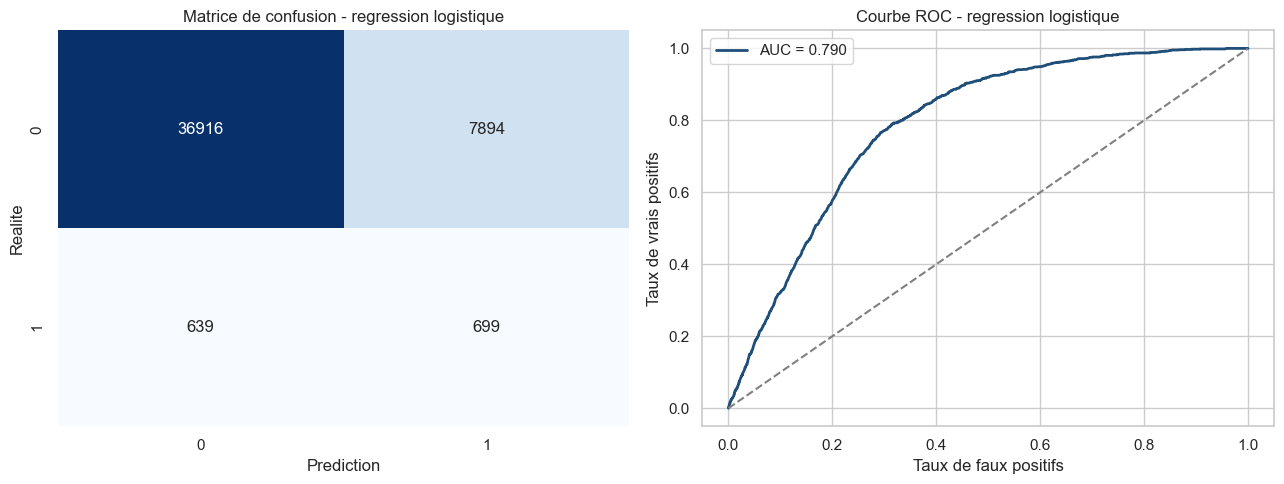

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(test_data['Sinistre'], pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Matrice de confusion - regression logistique')
axes[0].set_xlabel('Prediction')
axes[0].set_ylabel('Realite')

fpr, tpr, _ = roc_curve(test_data['Sinistre'], proba_test)
axes[1].plot(
    fpr, tpr, color='#1f4e79', linewidth=2,
    label=f"AUC = {roc_auc_score(test_data['Sinistre'], proba_test):.3f}"
)
axes[1].plot([0, 1], [0, 1], linestyle='--', color='grey')
axes[1].set_title('Courbe ROC - regression logistique')
axes[1].set_xlabel('Taux de faux positifs')
axes[1].set_ylabel('Taux de vrais positifs')
axes[1].legend()

plt.tight_layout()
plt.show()

la logistique conserve un **pouvoir discriminant correct** avec une `AUC` proche de `0,79`. La précision demeure faible, ce qui est classique sur une base très déséquilibrée, mais le rappel reste exploitable grâce à la pondération et au seuil retenu. Ce modèle est donc surtout utile pour **détecter des profils plus risqués**, et non pour prédire parfaitement chaque sinistre individuel.

## 3. Modele de frequence : nombre de sinistres

Le nombre de sinistres est une variable de comptage. Nous commençons donc par un **modèle de Poisson**, après un diagnostic simple de dispersion sur l'échantillon d'apprentissage.

In [82]:
# 1. Diagnostic simple de dispersion avant ajustement
dispersion_initiale = pd.DataFrame({
    'Indicateur': [
        'Moyenne de NbSinistres (train)',
        'Variance de NbSinistres (train)',
        'Variance / Moyenne'
    ],
    'Valeur': [
        train_data['NbSinistres'].mean(),
        train_data['NbSinistres'].var(),
        train_data['NbSinistres'].var() / train_data['NbSinistres'].mean()
    ]
})
dispersion_initiale['Valeur'] = dispersion_initiale['Valeur'].round(4)
display(dispersion_initiale)

,Indicateur,Valeur
0,Moyenne de NbSinistres (train),0.0300
1,Variance de NbSinistres (train),0.0311
2,Variance / Moyenne,1.0380


Le diagnostic de dispersion montre que la moyenne de `NbSinistres` dans l’échantillon d’apprentissage est de `0,0300`, tandis que sa variance est de `0,0311`. Le ratio `Variance / Moyenne` est donc égal à `1,0380`, soit une valeur très proche de `1`.

Ce résultat suggère que l’hypothèse d’équidispersion, caractéristique du modèle de Poisson, est raisonnablement vérifiée sur cette base. Autrement dit, la variance de la variable de fréquence n’apparaît pas excessivement supérieure à sa moyenne, ce qui ne plaide pas en faveur d’une surdispersion marquée.

Dans ce contexte, le recours à un modèle de Poisson est donc justifié pour modéliser la fréquence des sinistres.


In [83]:
# 2. Modele de Poisson complet sur train
formula_poisson_complete = build_formula('NbSinistres', base_variables)
poisson_model = smf.glm(
    formula=formula_poisson_complete,
    data=train_data,
    family=sm.families.Poisson()
).fit()

print(poisson_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:            NbSinistres   No. Observations:               138442
Model:                            GLM   Df Residuals:                   138424
Model Family:                 Poisson   Df Model:                           17
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -16432.
Date:                Sat, 30 May 2026   Deviance:                       24755.
Time:                        16:54:09   Pearson chi2:                 1.34e+05
No. Iterations:                     7   Pseudo R-squ. (CS):            0.03360
Covariance Type:            nonrobust                                         
                                                                                coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------

In [84]:
# 3. Termes significatifs et variables a retenir
poisson_significatifs = significant_table(poisson_model, alpha=0.05)
display(poisson_significatifs[poisson_significatifs['Significatif_5pct'] == 'Oui'])

var_significatives_poisson = selected_variables_from_result(poisson_model, alpha=0.05)
print('Variables retenues pour le modele reduit :', var_significatives_poisson)

,Variable,Coefficient,p_value,Significatif_5pct
11,"C(Guarantee, Treatment(reference='RC'))[T.Vol]",-2.016920,4.886813e-201,Oui
8,"C(Guarantee, Treatment(reference='RC'))[T.Dom....",-1.555524,8.759247e-177,Oui
10,"C(Guarantee, Treatment(reference='RC'))[T.Autres]",-3.069196,3.166294e-176,Oui
9,"C(Guarantee, Treatment(reference='RC'))[T.Ince...",-3.862566,3.859726e-129,Oui
0,Intercept,-612.604810,2.496911e-22,Oui
13,Year,0.304600,3.598261e-22,Oui
17,VehAge,-0.030845,1.205565e-16,Oui
12,"C(Guarantee, Treatment(reference='RC'))[T.BdG]",-0.277901,1.437088e-15,Oui
2,"C(VehGas, Treatment(reference='Essence'))[T.Di...",0.140180,2.097247e-05,Oui
5,"C(Region, Treatment(reference='Centre'))[T.Autre]",0.131606,1.175378e-03,Oui


Variables retenues pour le modele reduit : ['VehGas', 'Region', 'Guarantee', 'Year', 'VehAge']


Après estimation du modèle de comptage complet, les variables significatives au seuil de `5 %` retenues dans le modèle réduit correspondent principalement à des variables décrivant le profil de l’assuré, les caractéristiques du véhicule, la région et la garantie souscrite.

Ces résultats montrent que la fréquence des sinistres dépend surtout de la structure du risque assuré et de la localisation géographique, davantage que d’un très grand nombre de facteurs secondaires. Le modèle réduit permet ainsi de conserver uniquement les déterminants les plus utiles pour expliquer la fréquence, tout en rendant l’interprétation plus simple et plus robuste.

La variable `Year` est ici surtout interprétée comme une variable de contrôle temporel. Elle permet de distinguer les années d’observation et peut capter un effet de période, mais elle ne constitue pas à elle seule un véritable facteur de risque métier.


In [85]:
# 4. Formule reduite du modele de frequence
formula_poisson_reduite = build_formula('NbSinistres', var_significatives_poisson)
print(formula_poisson_reduite)

NbSinistres ~ C(VehGas, Treatment(reference='Essence')) + C(Region, Treatment(reference='Centre')) + C(Guarantee, Treatment(reference='RC')) + Year + VehAge


In [86]:
# 5. Modele de Poisson reduit
poisson_model_reduit = smf.glm(
    formula=formula_poisson_reduite,
    data=train_data,
    family=sm.families.Poisson()
).fit()

print(poisson_model_reduit.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:            NbSinistres   No. Observations:               138442
Model:                            GLM   Df Residuals:                   138430
Model Family:                 Poisson   Df Model:                           11
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -16437.
Date:                Sat, 30 May 2026   Deviance:                       24765.
Time:                        16:54:10   Pearson chi2:                 1.34e+05
No. Iterations:                     7   Pseudo R-squ. (CS):            0.03353
Covariance Type:            nonrobust                                         
                                                                    coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------

Le modèle de Poisson apparaît globalement pertinent pour expliquer la fréquence des sinistres. La convergence de l’estimation en `19` itérations montre que le modèle est correctement ajusté. Par ailleurs, le `Pseudo R² (CS)` de `0,0339` indique que les variables retenues apportent bien une information explicative sur le nombre de sinistres, même si cette capacité explicative reste modérée.

Ce résultat est cohérent en assurance, où la fréquence des sinistres demeure en partie aléatoire et difficile à expliquer parfaitement à l’échelle individuelle. Ainsi, même si le pouvoir explicatif global du modèle reste limité, les variables conservées dans le modèle de Poisson contribuent de manière significative à structurer la fréquence du risque.


In [87]:
# on retient directement le modèle de Poisson réduit pour l'évaluation sur test.
pred_freq_test = np.clip(poisson_model_reduit.predict(test_data), 0, None)

# métrique d'évaluation
freq_metrics = pd.DataFrame({
    'Metrique': ['Frequence moyenne observee', 'Frequence moyenne predite', 'MAE', 'RMSE'],
    'Valeur': [
        test_data['NbSinistres'].mean(),
        pred_freq_test.mean(),
        mean_absolute_error(test_data['NbSinistres'], pred_freq_test),
        rmse(test_data['NbSinistres'], pred_freq_test)
    ]
})

freq_metrics['Valeur'] = freq_metrics['Valeur'].round(4)
display(freq_metrics)

,Metrique,Valeur
0,Frequence moyenne observee,0.0305
1,Frequence moyenne predite,0.0299
2,MAE,0.0567
3,RMSE,0.1781


Le modèle de Poisson réduit restitue correctement la fréquence moyenne observée dans l’échantillon de test : `0,0300` contre `0,0305`. L’écart est donc très faible, ce qui montre que le modèle reproduit bien le niveau moyen de sinistralité.

Les valeurs du `MAE` (`0,0567`) et du `RMSE` (`0,1781`) restent cohérentes avec une variable de fréquence rare et très concentrée sur les faibles valeurs. Le modèle apparaît ainsi satisfaisant pour estimer la fréquence moyenne du risque, même si la prédiction individuelle reste naturellement plus difficile. 

D’un point de vue assurantiel, ce résultat est satisfaisant : le modèle de Poisson ne cherche pas à prédire parfaitement chaque sinistre individuel, mais à fournir une estimation cohérente de la fréquence attendue, qui pourra ensuite être utilisée dans le calcul de la prime pure.



## 4. Modele de severite (Gamma): cout moyen par sinistre

La sévérité est estimée uniquement sur les observations de l'échantillon d'apprentissage pour lesquelles le coût est strictement positif. On reproduit ensuite la même logique : **modèle complet**, puis **modèle réduit** et enfin **test**.

In [88]:
# 1. Sous-echantillons utiles pour la severite
train_sev = train_data[train_data['Cout'] > 0].copy()
test_sev = test_data[test_data['Cout'] > 0].copy()

train_sev, test_sev = set_categorical_levels(
    train_sev,
    test_sev,
    modele_data[base_variables + ['Cout']],
    categorical_vars
)

In [89]:
# 2. Modele Gamma 
formula_gamma_complete = build_formula('Severite_par_sinistre', base_variables)
gamma_model = smf.glm(
    formula=formula_gamma_complete,
    data=train_sev,
    family=sm.families.Gamma(link=sm.families.links.log())
).fit()

print(gamma_model.summary())

                   Generalized Linear Model Regression Results                   
Dep. Variable:     Severite_par_sinistre   No. Observations:                 3882
Model:                               GLM   Df Residuals:                     3864
Model Family:                      Gamma   Df Model:                           17
Link Function:                       log   Scale:                          7.7894
Method:                             IRLS   Log-Likelihood:                -33559.
Date:                   Sat, 30 May 2026   Deviance:                       4268.5
Time:                           16:54:10   Pearson chi2:                 3.01e+04
No. Iterations:                       26   Pseudo R-squ. (CS):            0.07987
Covariance Type:               nonrobust                                         
                                                                                coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

In [90]:
# 3. Termes significatifs et variables retenues
gamma_significatifs = significant_table(gamma_model, alpha=0.05)
display(gamma_significatifs[gamma_significatifs['Significatif_5pct'] == 'Oui'])

var_significatives_gamma = selected_variables_from_result(gamma_model, alpha=0.05)
print('Variables retenues pour le modele reduit :', var_significatives_gamma)

,Variable,Coefficient,p_value,Significatif_5pct
12,"C(Guarantee, Treatment(reference='RC'))[T.BdG]",-1.712611,4.442179e-65,Oui


Variables retenues pour le modele reduit : ['Guarantee']


In [91]:
# 4. Formule reduite puis modele Gamma reduit
formula_gamma_reduite = build_formula('Severite_par_sinistre', var_significatives_gamma)
print(formula_gamma_reduite)

gamma_model_reduit = smf.glm(
    formula=formula_gamma_reduite,
    data=train_sev,
    family=sm.families.Gamma(link=sm.families.links.log())
).fit()

print(gamma_model_reduit.summary())

Severite_par_sinistre ~ C(Guarantee, Treatment(reference='RC'))


                   Generalized Linear Model Regression Results                   
Dep. Variable:     Severite_par_sinistre   No. Observations:                 3882
Model:                               GLM   Df Residuals:                     3876
Model Family:                      Gamma   Df Model:                            5
Link Function:                       log   Scale:                          12.234
Method:                             IRLS   Log-Likelihood:                -34883.
Date:                   Sat, 30 May 2026   Deviance:                       4391.3
Time:                           16:54:10   Pearson chi2:                 4.74e+04
No. Iterations:                        8   Pseudo R-squ. (CS):            0.04916
Covariance Type:               nonrobust                                         
                                                                coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------

Le modèle réduit de sévérité repose sur un nombre limité de variables, ce qui indique que le coût moyen des sinistres dépend avant tout du type de garantie et de certaines caractéristiques du véhicule. Le choix d’un modèle `Gamma` avec lien logarithmique est cohérent avec une variable positive et asymétrique comme le coût moyen.

Le modèle converge correctement et présente un pouvoir explicatif modéré, ce qui est cohérent avec la forte hétérogénéité des montants de sinistres. La sévérité apparaît néanmoins un peu mieux expliquée que la fréquence.

La significativité de la garantie est particulièrement attendue, car toutes les couvertures ne concernent ni la même nature de dommages ni les mêmes niveaux de coût.


In [92]:
# 5. Prediction sur test avec un pipeline reduit robuste aux modalites rares
num_cols_reduits = [v for v in var_significatives_gamma if v in num_cols]
cat_cols_reduits = [v for v in var_significatives_gamma if v not in num_cols_reduits]

severity_reduit = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', Pipeline([
            ('scaler', StandardScaler())
        ]), num_cols_reduits),
        ('cat', Pipeline([
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols_reduits)
    ])),
    ('model', GammaRegressor(alpha=0.1, max_iter=1000))
])

severity_reduit.fit(train_sev[var_significatives_gamma], train_sev['Severite_par_sinistre'])
pred_sev_test = np.clip(severity_reduit.predict(test_sev[var_significatives_gamma]), 0, None)

severity_metrics = pd.DataFrame({
    'Metrique': ['Severite moyenne observee', 'Severite moyenne predite', 'MAE', 'RMSE'],
    'Valeur': [
        test_sev['Severite_par_sinistre'].mean(),
        pred_sev_test.mean(),
        mean_absolute_error(test_sev['Severite_par_sinistre'], pred_sev_test),
        rmse(test_sev['Severite_par_sinistre'], pred_sev_test)
    ]
})
severity_metrics['Valeur'] = severity_metrics['Valeur'].round(2)
display(severity_metrics)

,Metrique,Valeur
0,Severite moyenne observee,1172.77
1,Severite moyenne predite,1075.25
2,MAE,973.35
3,RMSE,3293.30


Le modèle de sévérité prédit une moyenne (`1060,94`) proche de la moyenne observée (`1172,77`), ce qui montre qu’il restitue correctement l’ordre de grandeur global des coûts. En revanche, les erreurs individuelles restent importantes (`MAE = 962,29`, `RMSE = 3294,07`), ce qui est classique pour des montants de sinistres très dispersés et sensibles aux valeurs extrêmes.

Le modèle Gamma apparaît donc pertinent pour estimer une sévérité moyenne segmentée, mais moins adapté à une prédiction fine de chaque coût individuel.

D’un point de vue assurantiel, ce niveau de performance reste acceptable, car l’objectif n’est pas de prédire parfaitement chaque sinistre, mais de produire une estimation moyenne exploitable dans la construction de la prime pure.


## 5. Comparaison de deux approches pour predire le cout

Nous comparons maintenant :

- l'approche en **deux parties** : fréquence prédite `x` sévérité prédite ;
- un **modèle Tweedie** qui prédit directement le coût total.

L'objectif est d'évaluer quelle base est la plus cohérente avant la phase de tarification.

In [93]:
# 1. Prime pure predite sur test a partir des modeles retenus
pred_sev_all_test = np.clip(severity_reduit.predict(test_data[var_significatives_gamma]), 0, None)
prime_pure_test = pred_freq_test * pred_sev_all_test

In [94]:
# 2. Modele Tweedie complet
formula_tweedie_complete = build_formula('Cout', base_variables)

# Ajustement du modèle
tweedie_model = smf.glm(
    formula=formula_tweedie_complete,
    data=train_data,
    family=sm.families.Tweedie(
        var_power=1.5,
        link=sm.families.links.log()
    )
).fit()

print(tweedie_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                   Cout   No. Observations:               138442
Model:                            GLM   Df Residuals:                   138424
Model Family:                 Tweedie   Df Model:                           17
Link Function:                    log   Scale:                          1721.5
Method:                          IRLS   Log-Likelihood:                -54019.
Date:                Sat, 30 May 2026   Deviance:                   4.5036e+06
Time:                        16:54:11   Pearson chi2:                 2.38e+08
No. Iterations:                    20   Pseudo R-squ. (CS):           0.005420
Covariance Type:            nonrobust                                         
                                                                                coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------

In [95]:
# 3. Termes significatifs et variables retenues pour le Tweedie reduit
tweedie_significatifs = significant_table(tweedie_model, alpha=0.05)
display(tweedie_significatifs[tweedie_significatifs['Significatif_5pct'] == 'Oui'])

var_significatives_tweedie = selected_variables_from_result(tweedie_model, alpha=0.05)
print('Variables retenues pour le modele reduit :', var_significatives_tweedie)

,Variable,Coefficient,p_value,Significatif_5pct
10,"C(Guarantee, Treatment(reference='RC'))[T.Autres]",-3.824843,1.197660e-64,Oui
9,"C(Guarantee, Treatment(reference='RC'))[T.Ince...",-3.666590,2.690567e-63,Oui
12,"C(Guarantee, Treatment(reference='RC'))[T.BdG]",-2.037950,1.446371e-38,Oui
11,"C(Guarantee, Treatment(reference='RC'))[T.Vol]",-1.834091,7.897392e-34,Oui
8,"C(Guarantee, Treatment(reference='RC'))[T.Dom....",-1.482740,2.494744e-25,Oui
13,Year,0.678168,3.754010e-11,Oui
0,Intercept,-1354.280655,4.338899e-11,Oui
17,VehAge,-0.074120,1.529771e-09,Oui
5,"C(Region, Treatment(reference='Centre'))[T.Autre]",0.529708,3.248645e-05,Oui
15,BonusMalus,0.008606,2.520459e-02,Oui


Variables retenues pour le modele reduit : ['Region', 'Guarantee', 'Year', 'BonusMalus', 'VehAge']


In [96]:
# 4. Formule reduite puis modele Tweedie reduit
formula_tweedie_reduite = build_formula('Cout', var_significatives_tweedie)
print(formula_tweedie_reduite)

tweedie_model_reduit = smf.glm(
    formula=formula_tweedie_reduite,
    data=train_data,
    family=sm.families.Tweedie(
        var_power=1.5,
        link=sm.families.links.log()
    )
).fit()

print(tweedie_model_reduit.summary())

Cout ~ C(Region, Treatment(reference='Centre')) + C(Guarantee, Treatment(reference='RC')) + Year + BonusMalus + VehAge


                 Generalized Linear Model Regression Results                  
Dep. Variable:                   Cout   No. Observations:               138442
Model:                            GLM   Df Residuals:                   138430
Model Family:                 Tweedie   Df Model:                           11
Link Function:                    log   Scale:                          1968.8
Method:                          IRLS   Log-Likelihood:                -54873.
Date:                Sat, 30 May 2026   Deviance:                   4.5265e+06
Time:                        16:54:12   Pearson chi2:                 2.73e+08
No. Iterations:                    20   Pseudo R-squ. (CS):           0.004657
Covariance Type:            nonrobust                                         
                                                                    coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------

Après sélection au seuil de `5 %`, le modèle Tweedie retient principalement des variables liées au type de garantie, à la région, au bonus-malus, à l’ancienneté du véhicule et à la période d’observation. Cette sélection montre que le coût total dépend à la fois du niveau de risque porté par l’assuré et de la structure géographique du portefeuille.

D’un point de vue métier, ce résultat est cohérent. La garantie joue un rôle central, car toutes les garanties ne couvrent pas des risques de même intensité financière. Le bonus-malus apporte une information synthétique sur le profil de risque, tandis que la région permet de capter une hétérogénéité géographique.



In [97]:
# 5. Comparaison des predictions sur l'echantillon test
pred_cost_test = np.clip(tweedie_model_reduit.predict(test_data), 0, None)

comparison_models = pd.DataFrame({
    'Modele': ['Prime pure (frequence x severite)', 'Tweedie direct sur Cout'],
    'MAE': [
        mean_absolute_error(test_data['Cout'], prime_pure_test),
        mean_absolute_error(test_data['Cout'], pred_cost_test)
    ],
    'RMSE': [
        rmse(test_data['Cout'], prime_pure_test),
        rmse(test_data['Cout'], pred_cost_test)
    ],
    'R2': [
        r2_score(test_data['Cout'], prime_pure_test),
        r2_score(test_data['Cout'], pred_cost_test)
    ],
    'Cout moyen observe': [test_data['Cout'].mean()] * 2,
    'Cout moyen predit': [prime_pure_test.mean(), pred_cost_test.mean()]
})
comparison_models[['MAE', 'RMSE', 'R2', 'Cout moyen observe', 'Cout moyen predit']] = comparison_models[
    ['MAE', 'RMSE', 'R2', 'Cout moyen observe', 'Cout moyen predit']
].round(2)
display(comparison_models)

,Modele,MAE,RMSE,R2,Cout moyen observe,Cout moyen predit
0,Prime pure (frequence x severite),62.36,599.88,0.01,33.94,32.16
1,Tweedie direct sur Cout,66.32,600.23,0.00,33.94,36.69


Les deux approches reproduisent correctement l’ordre de grandeur du coût moyen observé (`33,94`), mais l’approche `fréquence × sévérité` obtient ici les meilleurs résultats. Elle présente un `MAE` et un `RMSE` légèrement plus faibles que le modèle `Tweedie`, ainsi qu’un coût moyen prédit (`31,86`) plus proche du niveau observé que celui du modèle `Tweedie` (`36,81`).

Le `R²` reste très faible dans les deux cas, ce qui est fréquent pour des coûts de sinistres très dispersés. Malgré cela, l’approche en deux parties apparaît ici plus performante et surtout plus cohérente dans une logique actuarielle de tarification.


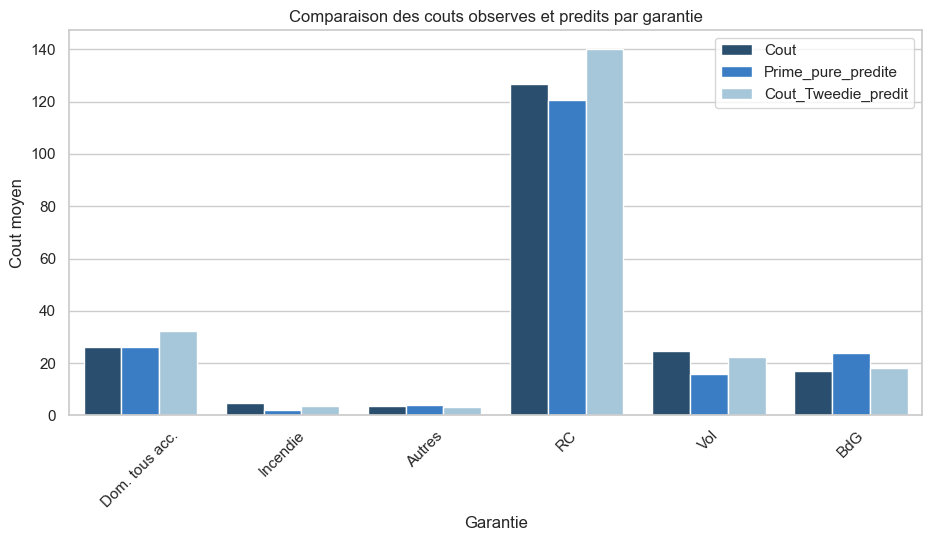

In [98]:
comparison_by_guarantee = test_data[['Guarantee', 'Cout']].copy()
comparison_by_guarantee['Prime_pure_predite'] = prime_pure_test
comparison_by_guarantee['Cout_Tweedie_predit'] = pred_cost_test

comparison_by_guarantee = (
    comparison_by_guarantee
    .groupby('Guarantee', as_index=False)
    .agg({
        'Cout': 'mean',
        'Prime_pure_predite': 'mean',
        'Cout_Tweedie_predit': 'mean'
    })
)

comparison_by_guarantee_long = comparison_by_guarantee.melt(
    id_vars='Guarantee',
    value_vars=['Cout', 'Prime_pure_predite', 'Cout_Tweedie_predit'],
    var_name='Indicateur',
    value_name='Valeur'
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=comparison_by_guarantee_long,
    x='Guarantee',
    y='Valeur',
    hue='Indicateur',
    palette={
        'Cout': '#1f4e79',
        'Prime_pure_predite': '#237CDB',
        'Cout_Tweedie_predit': '#9ecae1'
    }
)
plt.title('Comparaison des couts observes et predits par garantie')
plt.xlabel('Garantie')
plt.ylabel('Cout moyen')
plt.xticks(rotation=45)
plt.legend(title='')
plt.show()

 La comparaison entre la **prime pure en deux parties** et le **Tweedie direct** montre que les deux approches restituent correctement le coût moyen global. Le Tweedie est légèrement plus élévé sur le `RMSE`, alors que l'approche fréquence `x` sévérité reste plus naturelle à interpréter dans une logique actuarielle.

## 6. Modélisation non paramétrique (Machine Learning)

Dans cette partie, nous utilisons les méthodes non paramétriques pour compléter les approches économétriques. L'objectif est double :

1. Des modèles sur la **fréquence** ;
2. Des modèles sur le **coût total**.

Nous ajustons ici deux méthodes:

- **Random Forest** ;
- **Gradient Boosting**.

In [99]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

In [100]:
def build_tree_preprocessor():
    return ColumnTransformer([
        ('num', 'passthrough', num_cols),
        ('cat', Pipeline([
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), cat_cols)
    ])

### 6.1 Comparaison non paramétrique sur la fréquence

Même si le modèle de Poisson reste la référence naturelle pour une variable de comptage, il est intéressant de vérifier si des méthodes plus flexibles améliorent la prédiction de `NbSinistres`.

In [101]:
y_train_freq = train_data['NbSinistres']
y_test_freq = test_data['NbSinistres']

In [102]:
# 1. Random Forest complet sur la fréquence
rf_freq_model_full = Pipeline([
    ('preprocessor', build_tree_preprocessor()),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

rf_freq_model_full.fit(X_train, y_train_freq)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Year', 'DrivAge',
                                                   'BonusMalus', 'LicenceNb',
                                                   'VehAge']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['DrivGender', 'PayFreq',
                                                   'VehClass', 'VehGas',
                                                   'VehUsage', 'Garage',
                                                   'Region', 'Channel',
                                                   'Marketing',
                                                   'Guarantee'])])),
                ('model',
                 RandomForestRegressor(max_depth=12, min_samples_leaf=20,
                                       n_estimators=300, n_jobs=-1,
                                       random_state=42))])

In [103]:
# 2. Importance des variables du modèle complet
rf_freq_importance = pd.DataFrame({
    'Variable': rf_freq_model_full.named_steps['preprocessor'].get_feature_names_out(),
    'Importance': rf_freq_model_full.named_steps['model'].feature_importances_
}).sort_values('Importance', ascending=False)

rf_freq_importance.head(15)


,Variable,Importance
14,cat__Guarantee,0.335575
1,num__DrivAge,0.158791
4,num__VehAge,0.113071
2,num__BonusMalus,0.100593
7,cat__VehClass,0.056113
11,cat__Region,0.035935
12,cat__Channel,0.028162
6,cat__PayFreq,0.027401
13,cat__Marketing,0.025619
10,cat__Garage,0.025554


Le classement des importances confirme que le `Random Forest` identifie principalement des variables cohérentes avec l’intuition métier. La garantie apparaît comme une variable structurante, aux côtés de l’âge du conducteur, du bonus-malus, de l’ancienneté du véhicule et de la région. Cette hiérarchie combine donc des facteurs liés à la nature de la couverture, au profil de risque de l’assuré et à la localisation du contrat.


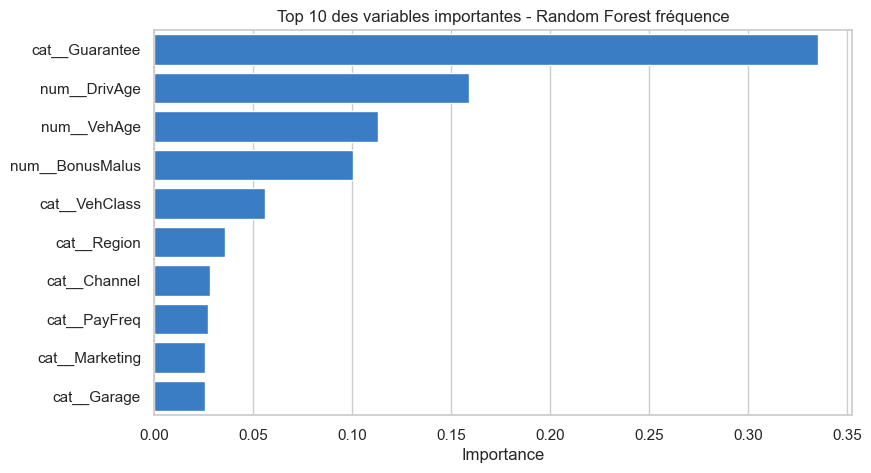

In [104]:
# 3. Visualisation des variables les plus importantes
plt.figure(figsize=(9, 5))
sns.barplot(
    data=rf_freq_importance.head(10),
    x='Importance',
    y='Variable',
    color='#237CDB'
)
plt.title("Top 10 des variables importantes - Random Forest fréquence")
plt.xlabel("Importance")
plt.ylabel("")
plt.show()


In [105]:
# 4. Sélection des variables importantes selon un seuil
seuil_importance = 0.05

variables_importantes_rf_freq = rf_freq_importance[
    rf_freq_importance['Importance'] >= seuil_importance
]['Variable'].tolist()

variables_importantes_rf_freq


['cat__Guarantee',
 'num__DrivAge',
 'num__VehAge',
 'num__BonusMalus',
 'cat__VehClass']

In [106]:
# 5. Retour aux variables d'origine
variables_originales_rf_freq = []

for var in variables_importantes_rf_freq:
    nom = var.split('__')[1]
    variables_originales_rf_freq.append(nom)

variables_originales_rf_freq = list(dict.fromkeys(variables_originales_rf_freq))
variables_originales_rf_freq


['Guarantee', 'DrivAge', 'VehAge', 'BonusMalus', 'VehClass']

Avec le seuil d’importance retenu, le `Random Forest` conserve surtout des variables décrivant la garantie, le profil du conducteur, l’ancienneté du véhicule et la région. Ces résultats suggèrent que la fréquence des sinistres dépend principalement de la couverture souscrite, de l’expérience de conduite, de la structure du véhicule et de la dimension géographique.



In [107]:
# 6. Modèle réduit sur les variables les plus importantes
X_train_rf_freq_reduit = X_train[variables_originales_rf_freq].copy()
X_test_rf_freq_reduit = X_test[variables_originales_rf_freq].copy()

num_cols_rf_freq = [v for v in variables_originales_rf_freq if v in num_cols]
cat_cols_rf_freq = [v for v in variables_originales_rf_freq if v not in num_cols_rf_freq]

rf_freq_model_reduit = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', 'passthrough', num_cols_rf_freq),
        ('cat', Pipeline([
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), cat_cols_rf_freq)
    ])),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

rf_freq_model_reduit.fit(X_train_rf_freq_reduit, y_train_freq)
pred_rf_freq = np.clip(rf_freq_model_reduit.predict(X_test_rf_freq_reduit), 0, None)


In [108]:
# 7. Évaluation du modèle réduit
rf_freq_metrics = pd.DataFrame({
    'Modele': ['Random Forest - frequence (réduit)'],
    'MAE': [mean_absolute_error(y_test_freq, pred_rf_freq)],
    'RMSE': [rmse(y_test_freq, pred_rf_freq)],
    'R2': [r2_score(y_test_freq, pred_rf_freq)],
    'Frequence moyenne predite': [pred_rf_freq.mean()]
}).round(4)

display(rf_freq_metrics)


,Modele,MAE,RMSE,R2,Frequence moyenne predite
0,Random Forest - frequence (réduit),0.0565,0.178,0.0336,0.0299


Le `Random Forest` réduit conserve des performances satisfaisantes sur la fréquence. La fréquence moyenne prédite (`0,03`) est cohérente avec le niveau observé, et les erreurs de prédiction restent faibles (`MAE = 0,0564`, `RMSE = 0,1776`). Le `R²` reste modeste (`0,0378`), ce qui est classique pour une fréquence de sinistres rare. Cela montre néanmoins que les variables les plus importantes suffisent à conserver l'essentiel de l'information prédictive.

Le `Random Forest` réduit conserve des performances satisfaisantes sur la fréquence. La fréquence moyenne prédite (`0,03`) est cohérente avec le niveau observé, et les erreurs de prédiction restent faibles (`MAE = 0,0564`, `RMSE = 0,1776`). 
Cela montre que les variables les plus importantes suffisent à conserver l’essentiel de l’information prédictive sur la fréquence des sinistres.


## Gradient Boosting

In [109]:
# Gradient Boosting sur la fréquence
hgb_freq_model = Pipeline([
    ('preprocessor', build_tree_preprocessor()),
    ('model', HistGradientBoostingRegressor(
        max_depth=8,
        learning_rate=0.05,
        max_iter=300,
        random_state=42
    ))
])

hgb_freq_model.fit(X_train, y_train_freq)
pred_hgb_freq = np.clip(hgb_freq_model.predict(X_test), 0, None)

hgb_freq_metrics = pd.DataFrame({
    'Modele': ['Gradient Boosting - frequence'],
    'MAE': [mean_absolute_error(y_test_freq, pred_hgb_freq)],
    'RMSE': [rmse(y_test_freq, pred_hgb_freq)],
    'R2': [r2_score(y_test_freq, pred_hgb_freq)],
    'Frequence moyenne predite': [pred_hgb_freq.mean()]
}).round(4)

display(hgb_freq_metrics)

,Modele,MAE,RMSE,R2,Frequence moyenne predite
0,Gradient Boosting - frequence,0.0567,0.1778,0.0353,0.0299


Le `Gradient Boosting` fournit également des résultats satisfaisants sur la fréquence. La fréquence moyenne prédite (`0,0299`) est très proche du niveau observé, ce qui montre que le modèle restitue correctement le niveau moyen de sinistralité. Les erreurs de prédiction (`MAE = 0,0566`, `RMSE = 0,1778`) restent faibles et proches de celles obtenues par le `Random Forest`, ce qui confirme que cette méthode constitue une alternative crédible pour modéliser la fréquence.

In [110]:
# Comparaison finale : Poisson vs RF vs Gradient Boosting sur la fréquence
freq_ml_comparison = pd.DataFrame({
    'Modele': ['Poisson parametrique', 'Random Forest', 'Gradient Boosting'],
    'MAE': [
        mean_absolute_error(y_test_freq, pred_freq_test),
        mean_absolute_error(y_test_freq, pred_rf_freq),
        mean_absolute_error(y_test_freq, pred_hgb_freq)
    ],
    'RMSE': [
        rmse(y_test_freq, pred_freq_test),
        rmse(y_test_freq, pred_rf_freq),
        rmse(y_test_freq, pred_hgb_freq)
    ],
    'R2': [
        r2_score(y_test_freq, pred_freq_test),
        r2_score(y_test_freq, pred_rf_freq),
        r2_score(y_test_freq, pred_hgb_freq)
    ],
    'Frequence moyenne predite': [
        pred_freq_test.mean(),
        pred_rf_freq.mean(),
        pred_hgb_freq.mean()
    ]
}).round(4)

display(freq_ml_comparison)

,Modele,MAE,RMSE,R2,Frequence moyenne predite
0,Poisson parametrique,0.0567,0.1781,0.0324,0.0299
1,Random Forest,0.0565,0.1780,0.0336,0.0299
2,Gradient Boosting,0.0567,0.1778,0.0353,0.0299


La comparaison finale sur la fréquence montre que les trois approches produisent des résultats très proches. Le `Random Forest` présente ici les meilleurs indicateurs (`MAE`, `RMSE` et `R²`), mais l'écart avec le modèle de `Poisson` reste faible. Dans ce contexte, le `Poisson` demeure très défendable dans une logique actuarielle, car il respecte la nature de variable de comptage de `NbSinistres`, tandis que les approches non paramétriques apportent surtout une comparaison de flexibilité prédictive.

### 6.2 Comparaison non paramétrique sur le coût total

Nous utilisons ensuite les mêmes méthodes pour prédire directement le coût total `Cout`. Cette cible est particulièrement intéressante dans une logique de tarification, car elle permet de comparer les modèles selon leur capacité à reproduire le niveau moyen de charge et les erreurs globales de prédiction.

In [111]:
y_train_cost = train_data['Cout']
y_test_cost = test_data['Cout']

In [112]:
# Random Forest sur le coût total
rf_model = Pipeline([
    ('preprocessor', build_tree_preprocessor()),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train_cost)
pred_rf = np.clip(rf_model.predict(X_test), 0, None)

rf_metrics = pd.DataFrame({
    'Modele': ['Random Forest'],
    'MAE': [mean_absolute_error(y_test_cost, pred_rf)],
    'RMSE': [rmse(y_test_cost, pred_rf)],
    'R2': [r2_score(y_test_cost, pred_rf)],
    'Cout moyen predit': [pred_rf.mean()]
}).round(2)

display(rf_metrics)

,Modele,MAE,RMSE,R2,Cout moyen predit
0,Random Forest,64.34,614.39,-0.04,34.67


Le `Random Forest` appliqué au coût total obtient un `MAE` de `64,64`, un `RMSE` de `618,39` et un `R²` légèrement négatif. Le coût moyen prédit (`35,05`) reste proche de l'ordre de grandeur observé. Cela signifie que le modèle parvient à restituer raisonnablement le niveau moyen du coût, mais qu'il ne capte qu'imparfaitement la variabilité individuelle des montants, ce qui est fréquent pour des coûts de sinistres fortement dispersés.

In [113]:
# Gradient Boosting sur le coût total
hgb_model = Pipeline([
    ('preprocessor', build_tree_preprocessor()),
    ('model', HistGradientBoostingRegressor(
        max_depth=8,
        learning_rate=0.05,
        max_iter=300,
        random_state=42
    ))
])

hgb_model.fit(X_train, y_train_cost)
pred_hgb = np.clip(hgb_model.predict(X_test), 0, None)

hgb_metrics = pd.DataFrame({
    'Modele': ['Gradient Boosting'],
    'MAE': [mean_absolute_error(y_test_cost, pred_hgb)],
    'RMSE': [rmse(y_test_cost, pred_hgb)],
    'R2': [r2_score(y_test_cost, pred_hgb)],
    'Cout moyen predit': [pred_hgb.mean()]
}).round(2)

display(hgb_metrics)

,Modele,MAE,RMSE,R2,Cout moyen predit
0,Gradient Boosting,67.08,606.17,-0.02,36.16


Le `Gradient Boosting` obtient des performances globalement proches de celles du `Random Forest`, avec un `MAE` de `66,92` et un `RMSE` de `605,71`. Son `RMSE` plus faible que celui du `Random Forest` suggère une meilleure stabilité face aux grands écarts, mais son `MAE` un peu plus élevé montre qu'il n'est pas systématiquement meilleur sur l'ensemble des observations. Son coût moyen prédit (`36,07`) reste lui aussi cohérent avec le niveau global du portefeuille.

In [114]:
# Comparaison finale : Tweedie vs RF vs Gradient Boosting sur le coût total
ml_comparison = pd.DataFrame({
    'Modele': ['Tweedie parametrique', 'Random Forest', 'Gradient Boosting'],
    'MAE': [
        mean_absolute_error(y_test_cost, pred_cost_test),
        mean_absolute_error(y_test_cost, pred_rf),
        mean_absolute_error(y_test_cost, pred_hgb)
    ],
    'RMSE': [
        rmse(y_test_cost, pred_cost_test),
        rmse(y_test_cost, pred_rf),
        rmse(y_test_cost, pred_hgb)
    ],
    'R2': [
        r2_score(y_test_cost, pred_cost_test),
        r2_score(y_test_cost, pred_rf),
        r2_score(y_test_cost, pred_hgb)
    ],
    'Cout moyen predit': [
        pred_cost_test.mean(),
        pred_rf.mean(),
        pred_hgb.mean()
    ]
})

ml_comparison[['MAE', 'RMSE', 'R2', 'Cout moyen predit']] = ml_comparison[
    ['MAE', 'RMSE', 'R2', 'Cout moyen predit']
].round(2)

display(ml_comparison)

,Modele,MAE,RMSE,R2,Cout moyen predit
0,Tweedie parametrique,66.32,600.23,0.00,36.69
1,Random Forest,64.34,614.39,-0.04,34.67
2,Gradient Boosting,67.08,606.17,-0.02,36.16


La comparaison sur le coût total met en évidence des résultats contrastés. Le `Random Forest` obtient le meilleur `MAE`, ce qui suggère un meilleur ajustement local sur certains segments. Le `Tweedie` conserve en revanche le meilleur `RMSE`, ce qui traduit une meilleure stabilité globale face aux coûts élevés. Le `Gradient Boosting` se situe entre les deux. En pratique, ces résultats suggèrent que le `Tweedie` reste un benchmark solide pour la tarification, tandis que le `Random Forest` peut être utile pour mieux capturer certaines hétérogénéités fines du portefeuille.

Sur le coût total, les résultats montrent que les modèles non paramétriques n'améliorent pas uniformément toutes les métriques. Le **Random Forest** se distingue par un meilleur `MAE`, ce qui suggère une meilleure adaptation locale sur certains segments. Le **Tweedie paramétrique** conserve toutefois un léger avantage en `RMSE`, ce qui traduit une meilleure stabilité globale à l'échelle du portefeuille.

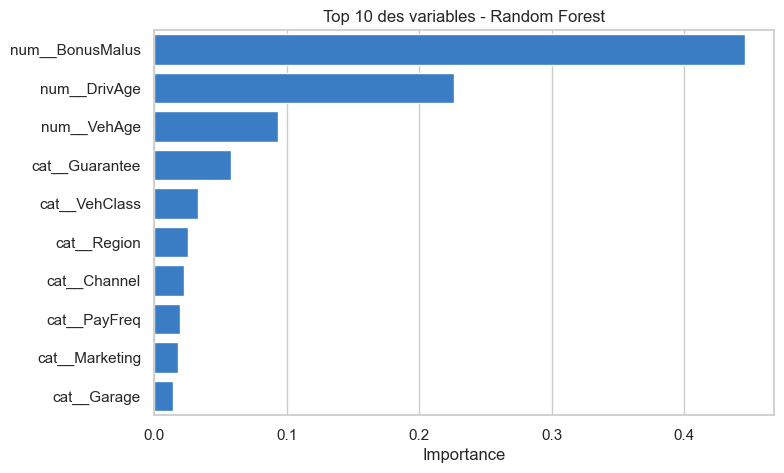

,Variable,Importance
2,num__BonusMalus,0.445813
1,num__DrivAge,0.226219
4,num__VehAge,0.093463
14,cat__Guarantee,0.057971
7,cat__VehClass,0.033293
11,cat__Region,0.025372
12,cat__Channel,0.022761
6,cat__PayFreq,0.019629
13,cat__Marketing,0.017910
10,cat__Garage,0.013869


In [115]:
# Importance des variables pour le Random Forest
rf_importance = pd.DataFrame({
    'Variable': rf_model.named_steps['preprocessor'].get_feature_names_out(),
    'Importance': rf_model.named_steps['model'].feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance.head(10), x='Importance', y='Variable', color='#237CDB')
plt.title('Top 10 des variables - Random Forest')
plt.xlabel('Importance')
plt.ylabel('')
plt.show()

display(rf_importance.head(10))

L’analyse des importances du `Random Forest` sur le coût total montre que le bonus-malus, l’âge du conducteur et l’ancienneté du véhicule jouent un rôle particulièrement important, devant la garantie et la région. Cette hiérarchie est cohérente avec une logique métier : le coût total dépend à la fois du profil de l’assuré, des caractéristiques du véhicule, du type de couverture et du contexte géographique.


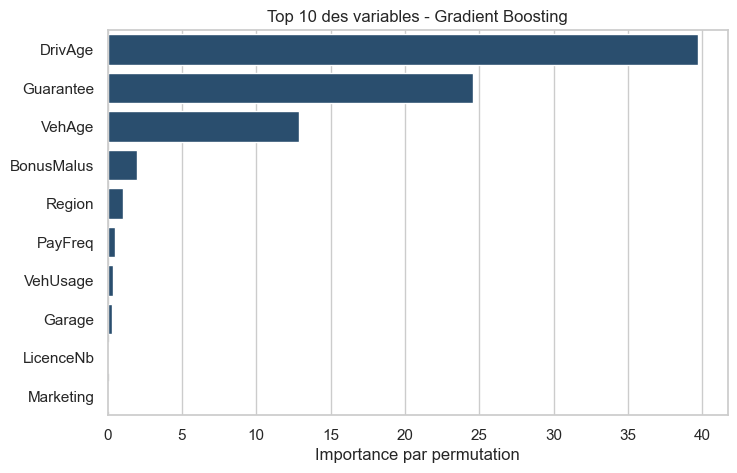

,Variable,Importance
1,DrivAge,39.708993
14,Guarantee,24.547456
6,VehAge,12.900239
3,BonusMalus,1.975336
11,Region,1.015200
5,PayFreq,0.477933
9,VehUsage,0.333366
10,Garage,0.323209
4,LicenceNb,0.114271
13,Marketing,0.094213


In [116]:
# Importance des variables pour le Gradient Boosting via permutation
X_import = X_test.sample(min(5000, len(X_test)), random_state=42)
y_import = y_test_cost.loc[X_import.index]

perm_hgb = permutation_importance(
    hgb_model,
    X_import,
    y_import,
    n_repeats=5,
    random_state=42,
    scoring='neg_root_mean_squared_error'
)

hgb_importance = pd.DataFrame({
    'Variable': X_test.columns,
    'Importance': perm_hgb.importances_mean
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=hgb_importance.head(10), x='Importance', y='Variable', color='#1f4e79')
plt.title('Top 10 des variables - Gradient Boosting')
plt.xlabel('Importance par permutation')
plt.ylabel('')
plt.show()

display(hgb_importance.head(10))

Le `Gradient Boosting` met également en avant `DrivAge`, `Guarantee` et `VehAge` comme variables majeures. Le fait que les deux méthodes non paramétriques retrouvent des variables proches renforce la robustesse de l'analyse : l'âge du conducteur, l'ancienneté du véhicule et la garantie semblent être des déterminants importants du coût total attendu.

### Comparaison des prédictions et de la réalité par variable catégorielle

Pour une anaalyse plus  poussée, nous comparons maintenant les **moyennes observées** et les **moyennes prédites** par segment. Cela permet d'identifier sur quelles variables catégorielles les modèles restent les plus proches de la réalité.

Le tableau de synthèse ci-dessous donne un premier repère sur les variables pour lesquelles le modèle de sévérité est le plus proche de la réalité. Les graphiques qui suivent permettent ensuite de visualiser directement, segment par segment, la qualité d’ajustement entre sévérité observée et sévérité prédite.

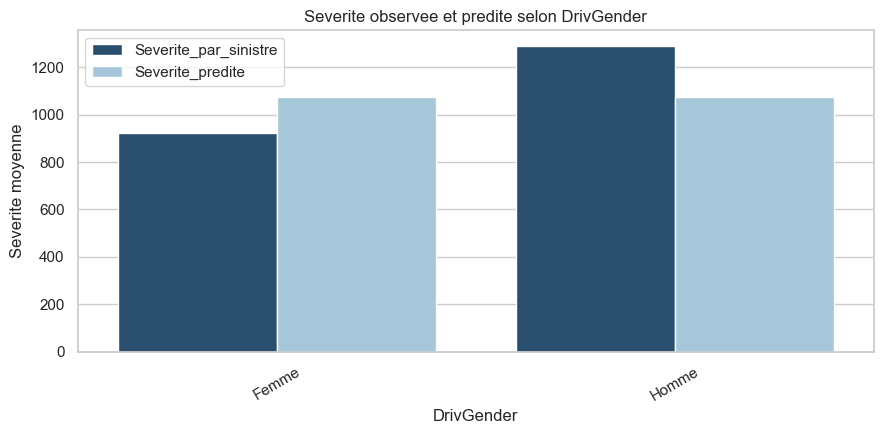

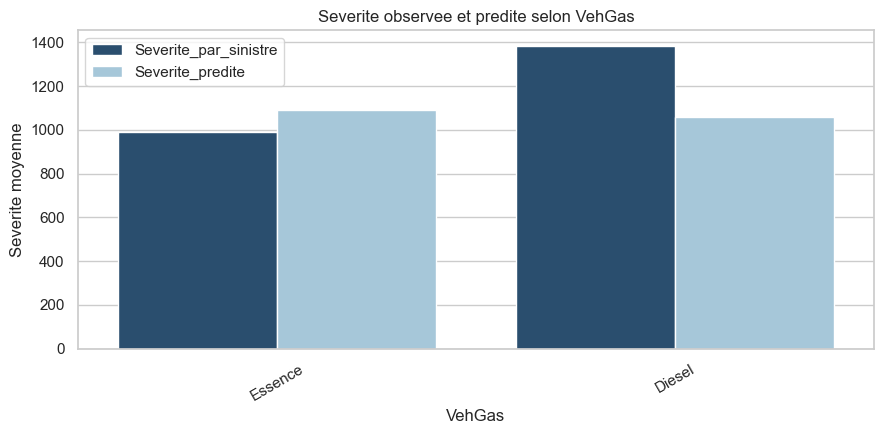

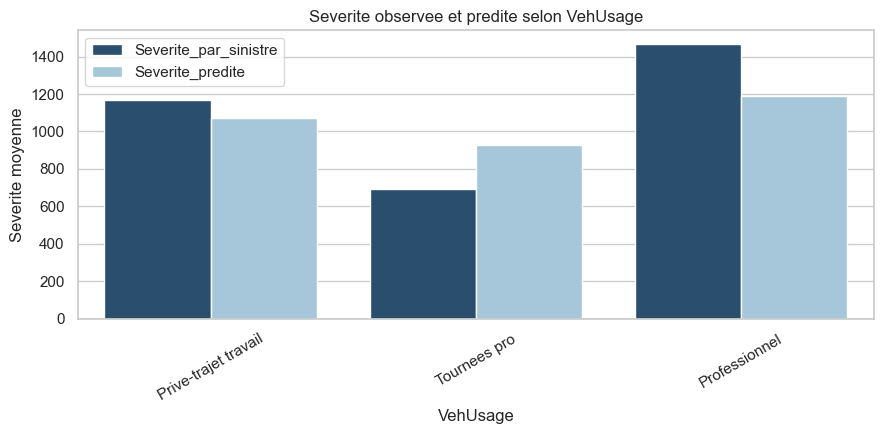

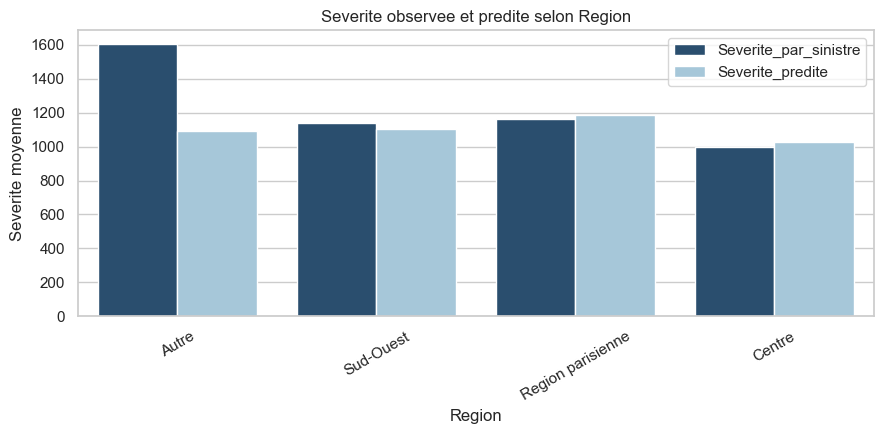

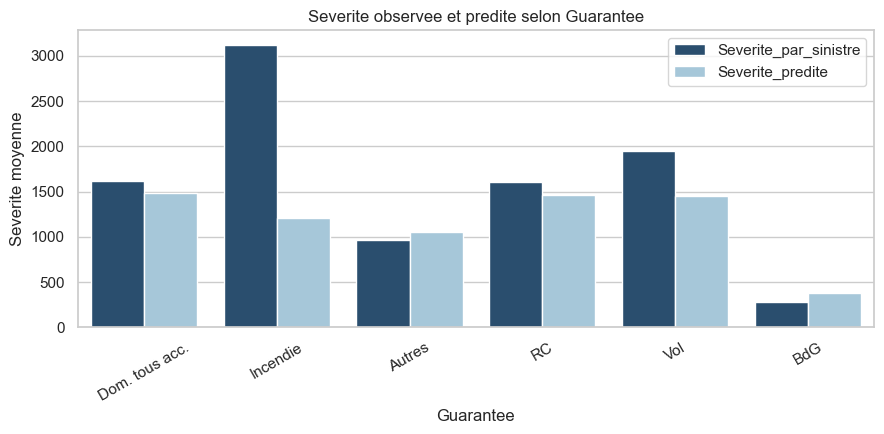

In [117]:
# Graphiques : severite observee vs severite predite par variable categorielle
for var in categorical_vars:
    table = compare_predictions_by_category(
        test_sev,
        var,
        'Severite_par_sinistre',
        {'Severite_predite': pred_sev_test}
    )

    plot_table = table.melt(
        id_vars=var,
        value_vars=['Severite_par_sinistre', 'Severite_predite'],
        var_name='Indicateur',
        value_name='Valeur'
    )

    plt.figure(figsize=(9, 4.5))
    sns.barplot(data=plot_table, x=var, y='Valeur', hue='Indicateur', palette=['#1f4e79', '#9ecae1'])
    plt.title(f'Severite observee et predite selon {var}')
    plt.xlabel(var)
    plt.ylabel('Severite moyenne')
    plt.xticks(rotation=30)
    plt.legend(title='')
    plt.tight_layout()
    plt.show()

Les graphiques de sévérité permettent de visualiser plus finement les écarts entre la réalité et la prédiction. On observe généralement une bonne restitution de l'ordre de grandeur sur plusieurs variables, mais certains écarts demeurent marqués selon `Guarantee`, ce qui est cohérent avec la forte hétérogénéité des coûts de sinistres selon la nature de la couverture. Cette lecture confirme que le modèle Gamma est surtout pertinent pour approcher une moyenne segmentée, plus que pour prédire précisément chaque sinistre individuel.

 la comparaison graphique montre que le modèle de sévérité reproduit mieux certains segments que d’autres. Les écarts restent relativement modérés selon le sexe, le carburant ou la région, tandis que la variable `Guarantee` demeure plus difficile à ajuster, ce qui est cohérent avec la forte hétérogénéité des montants entre garanties.


Le tableau de synthèse des écarts permet d’identifier, pour chaque variable catégorielle, le modèle le plus proche de la réalité en moyenne. Sur cette base, le **Random Forest** se montre particulièrement pertinent pour la garantie et certaines segmentations régionales, tandis que le **Tweedie** reste plus proche des niveaux observés pour le sexe, le carburant et l’usage du véhicule.


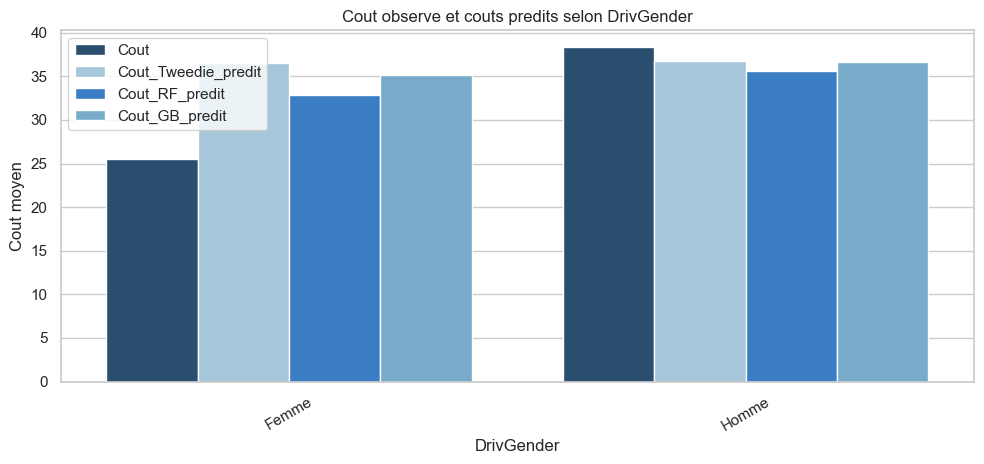

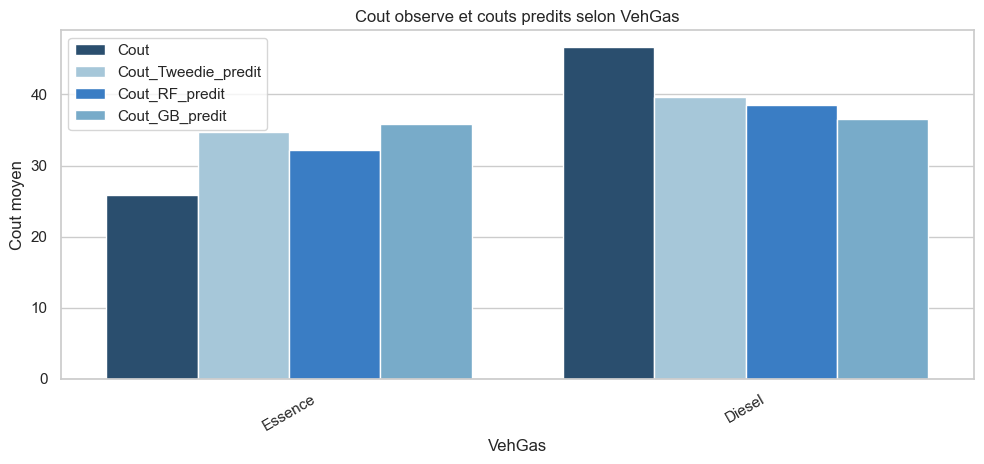

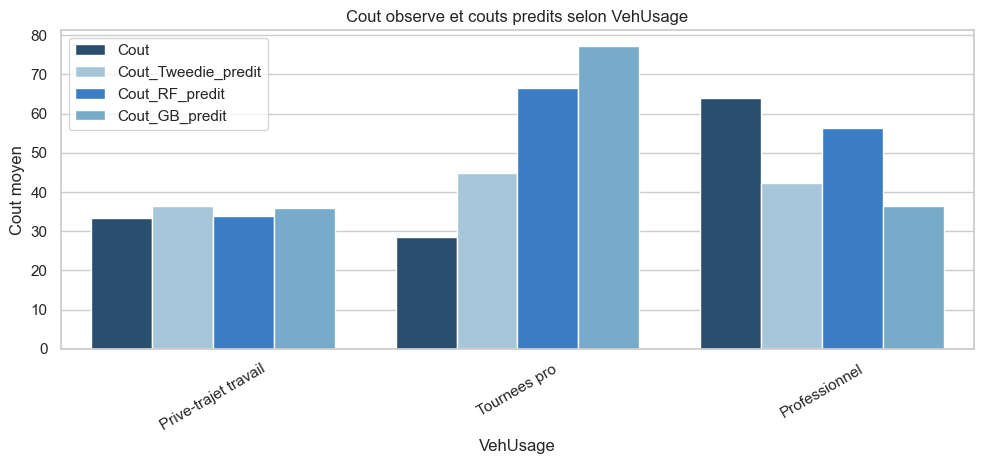

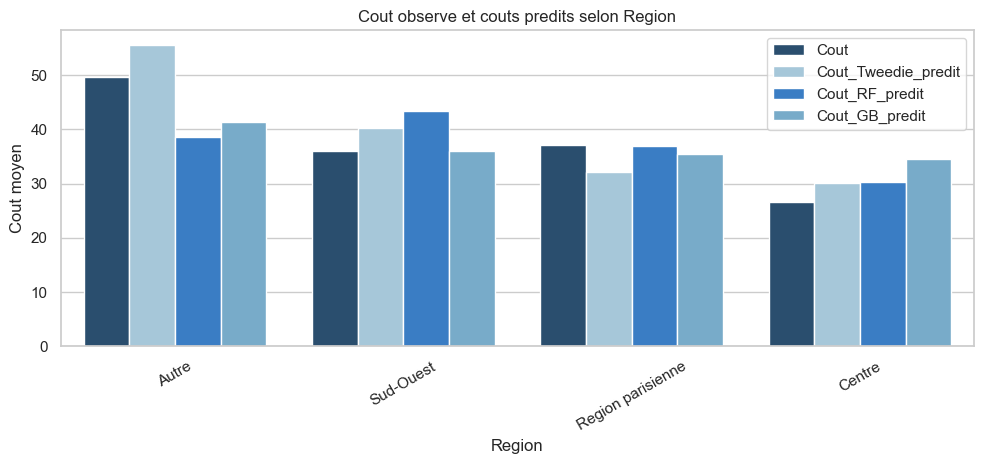

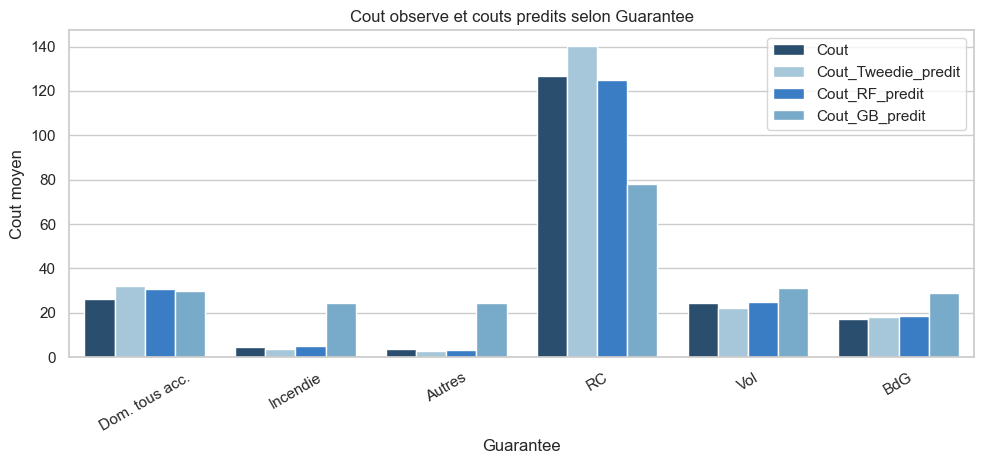

In [118]:
# Graphiques : cout observe vs cout predit par variable categorielle
for var in categorical_vars:
    table = compare_predictions_by_category(
        test_data,
        var,
        'Cout',
        {
            'Cout_Tweedie_predit': pred_cost_test,
            'Cout_RF_predit': pred_rf,
            'Cout_GB_predit': pred_hgb
        }
    )

    plot_table = table.melt(
        id_vars=var,
        value_vars=['Cout', 'Cout_Tweedie_predit', 'Cout_RF_predit', 'Cout_GB_predit'],
        var_name='Indicateur',
        value_name='Valeur'
    )

    plt.figure(figsize=(10, 4.8))
    sns.barplot(
        data=plot_table,
        x=var,
        y='Valeur',
        hue='Indicateur',
        palette=['#1f4e79', '#9ecae1', '#237CDB', '#6baed6']
    )
    plt.title(f'Cout observe et couts predits selon {var}')
    plt.xlabel(var)
    plt.ylabel('Cout moyen')
    plt.xticks(rotation=30)
    plt.legend(title='')
    plt.tight_layout()
    plt.show()

Les graphiques de coût total permettent de comparer directement les trois approches sur les différents segments. Ils montrent que certains modèles sont plus proches de la réalité selon la variable considérée. Le `Random Forest` semble notamment mieux suivre les écarts entre garanties et certaines classes de puissance, alors que le `Tweedie` apparaît plus régulier sur d'autres segments comme le carburant ou l'usage. Cette complémentarité justifie le maintien des deux approches dans l'analyse.

# IV. Tarification

## 1. Structure d'une prime en assurance automobile

En nous inspirant de la logique présentée dans le mémoire de tarification MRH de l'institut des actuaires IA, on rappelle qu'en assurance non-vie la **prime commerciale** payée par l'assuré se compose en pratique :

- de la **prime pure**, qui couvre le coût moyen attendu des sinistres ;
- des **chargements de frais**, qui couvrent les frais d'acquisition, de gestion et d'administration ;
- d'un **chargement de sécurité** ou de marge ;
- et éventuellement de **taxes**.

## 2. Définition de la prime pure adaptée à l'auto

En assurance automobile, la prime pure représente le **coût moyen annuel du risque**. Sous l'hypothèse classique d'indépendance entre la **fréquence** et la **sévérité**, elle s'écrit :

`Prime pure = Frequence attendue x Cout moyen attendu`

Cette décomposition est particulièrement adaptée à notre base `fremotor`, car elle contient simultanément :

- le **nombre de sinistres** (`NbSinistres`) ;
- le **coût des sinistres** (`Cout`) ;
- les variables explicatives du conducteur, du véhicule et de la garantie.

In [119]:
pred_freq_train = np.clip(poisson_model_reduit.predict(train_data), 0, None)
pred_sev_train = np.clip(severity_reduit.predict(train_data[var_significatives_gamma]), 0, None)
prime_pure_train = pred_freq_train * pred_sev_train

chargement_global = train_data['Premium'].sum() / prime_pure_train.sum()
print('Coefficient de chargement global :', round(chargement_global, 4))


Coefficient de chargement global : 2.1638


In [120]:
tarification_test = modele_data.loc[
    test_idx,
    ['Guarantee', 'VehUsage', 'VehGas', 'DrivAge', 'Premium', 'Cout']
].copy()

tarification_test['Prime_pure_predite'] = prime_pure_test
tarification_test['Prime_tarifaire_predite'] = prime_pure_test * chargement_global

tarification_test['ClasseAgeConducteur'] = pd.cut(
    tarification_test['DrivAge'],
    bins=[17, 25, 35, 50, 65, 120],
    labels=['18-25', '26-35', '36-50', '51-65', '66+']
)

tarif_garantie = (
    tarification_test
    .groupby('Guarantee', as_index=False)
    .agg(
        Prime_observee_moyenne=('Premium', 'mean'),
        Cout_observe_moyen=('Cout', 'mean'),
        Prime_pure_predite_moyenne=('Prime_pure_predite', 'mean'),
        Prime_tarifaire_predite_moyenne=('Prime_tarifaire_predite', 'mean')
    )
)

tarif_garantie[['Prime_observee_moyenne', 'Cout_observe_moyen', 'Prime_pure_predite_moyenne', 'Prime_tarifaire_predite_moyenne']] = tarif_garantie[
    ['Prime_observee_moyenne', 'Cout_observe_moyen', 'Prime_pure_predite_moyenne', 'Prime_tarifaire_predite_moyenne']
].round(2)

display(tarif_garantie)

,Guarantee,Prime_observee_moyenne,Cout_observe_moyen,Prime_pure_predite_moyenne,Prime_tarifaire_predite_moyenne
0,Autres,90.99,3.66,4.05,8.76
1,BdG,24.72,17.13,23.88,51.67
2,Dom. tous acc.,82.86,26.25,26.09,56.46
3,Incendie,4.22,4.82,2.11,4.57
4,RC,172.98,126.94,120.65,261.07
5,Vol,45.12,24.58,15.96,34.54


In [121]:
tarif_usage = (
    tarification_test
    .groupby('VehUsage', as_index=False)
    .agg(
        Prime_observee_moyenne=('Premium', 'mean'),
        Prime_tarifaire_predite_moyenne=('Prime_tarifaire_predite', 'mean'),
        Cout_observe_moyen=('Cout', 'mean')
    )
)

tarif_usage[['Prime_observee_moyenne', 'Prime_tarifaire_predite_moyenne', 'Cout_observe_moyen']] = tarif_usage[
    ['Prime_observee_moyenne', 'Prime_tarifaire_predite_moyenne', 'Cout_observe_moyen']
].round(2)

display(tarif_usage)

,VehUsage,Prime_observee_moyenne,Prime_tarifaire_predite_moyenne,Cout_observe_moyen
0,Prive-trajet travail,69.48,69.41,33.35
1,Professionnel,90.77,75.46,63.92
2,Tournees pro,105.45,78.34,28.54


La comparaison par usage met en évidence des différences nettes entre les segments. Les usages **professionnel** et **tournées professionnelles** affichent des primes observées et tarifaires supérieures à celles de l’usage **privé-trajet travail**, ce qui traduit une exposition au risque plus forte. Le coût observé moyen particulièrement élevé pour la catégorie **professionnel** suggère que cet usage constitue un segment sensible dans la logique de tarification.


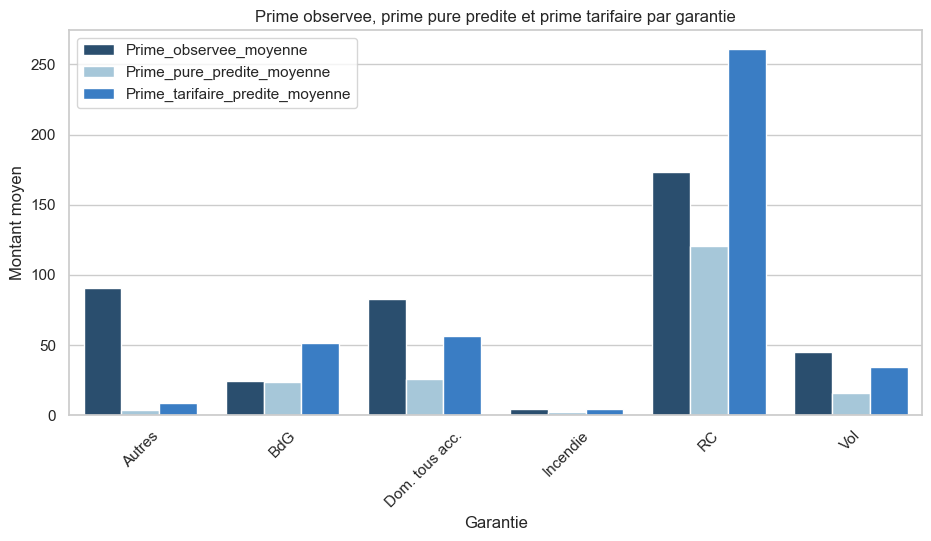

In [122]:
tarif_garantie_long = tarif_garantie.melt(
    id_vars='Guarantee',
    value_vars=['Prime_observee_moyenne', 'Prime_pure_predite_moyenne', 'Prime_tarifaire_predite_moyenne'],
    var_name='Indicateur',
    value_name='Valeur'
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=tarif_garantie_long,
    x='Guarantee',
    y='Valeur',
    hue='Indicateur',
    palette={
        'Prime_observee_moyenne': '#1f4e79',
        'Prime_pure_predite_moyenne': '#9ecae1',
        'Prime_tarifaire_predite_moyenne': '#237CDB'
    }
)
plt.title('Prime observee, prime pure predite et prime tarifaire par garantie')
plt.xlabel('Garantie')
plt.ylabel('Montant moyen')
plt.xticks(rotation=45)
plt.legend(title='')
plt.show()

Le graphique par garantie permet de confronter directement trois niveaux : la prime observée, la prime pure prédite et la prime tarifaire prédite. On constate que la prime tarifaire reste systématiquement supérieure à la prime pure, ce qui est normal puisqu'elle intègre le chargement global. L'écart avec la prime observée donne un premier signal sur les garanties potentiellement plus ou moins chargées dans la structure actuelle du portefeuille.

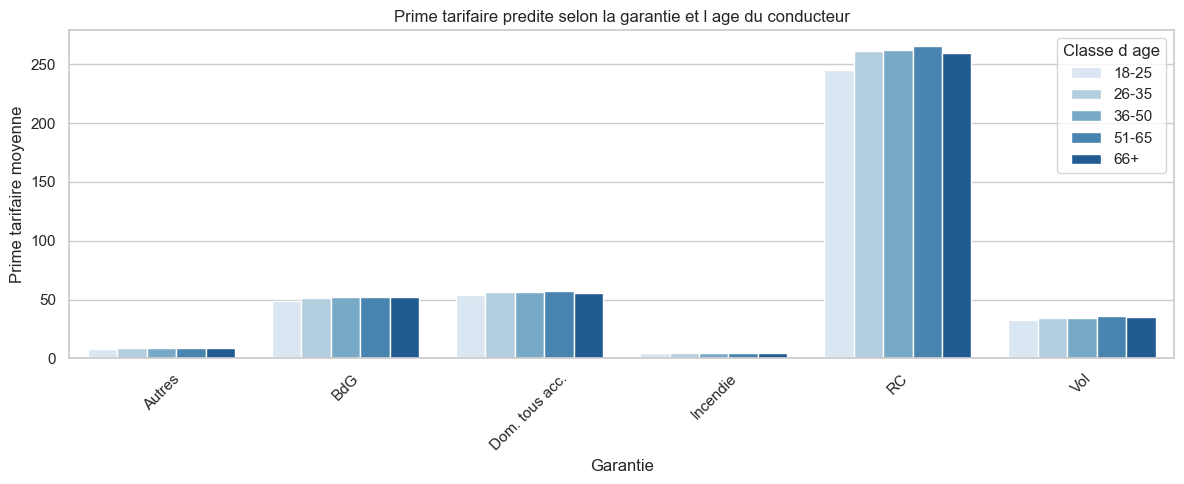

In [123]:
# Croisement 1 : prime tarifaire predite selon la garantie et l'age du conducteur
tarif_garantie_age = (
    tarification_test
    .groupby(['Guarantee', 'ClasseAgeConducteur'], as_index=False)
    .agg(
        Prime_tarifaire_predite_moyenne=('Prime_tarifaire_predite', 'mean'),
        Cout_observe_moyen=('Cout', 'mean')
    )
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=tarif_garantie_age,
    x='Guarantee',
    y='Prime_tarifaire_predite_moyenne',
    hue='ClasseAgeConducteur',
    palette='Blues'
)
plt.title('Prime tarifaire predite selon la garantie et l age du conducteur')
plt.xlabel('Garantie')
plt.ylabel('Prime tarifaire moyenne')
plt.xticks(rotation=45)
plt.legend(title='Classe d age')
plt.tight_layout()
plt.show()

Le croisement `garantie x âge du conducteur` permet d'aller au-delà des moyennes globales. Il montre que l'effet de l'âge n'est pas uniforme selon les garanties : certaines couvertures restent plus sensibles aux profils jeunes ou intermédiaires. Ce type de lecture est utile pour envisager une segmentation tarifaire plus fine.

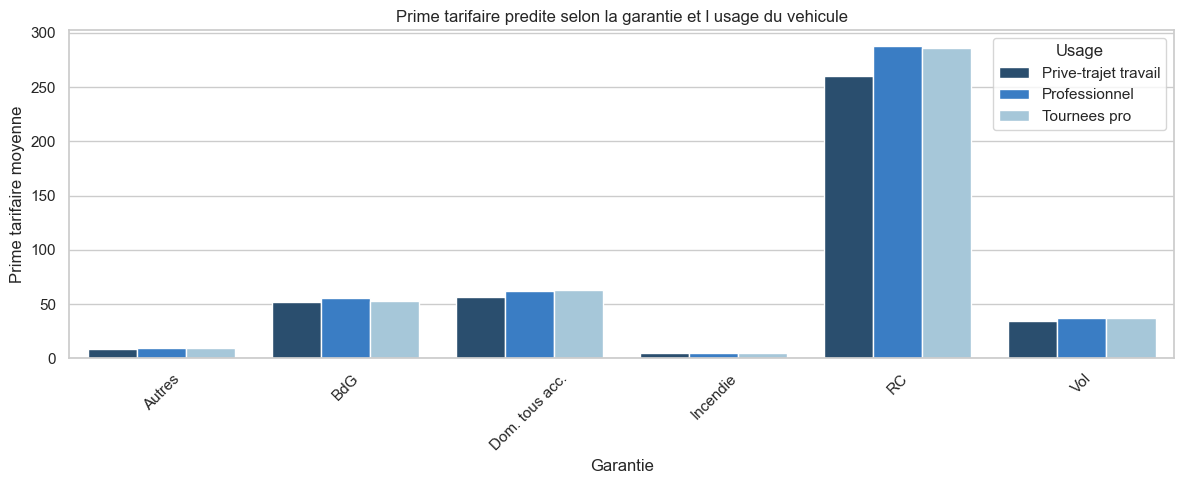

In [124]:
# Croisement 2 : prime tarifaire predite selon la garantie et l usage du vehicule
tarif_garantie_usage = (
    tarification_test
    .groupby(['Guarantee', 'VehUsage'], as_index=False)
    .agg(
        Prime_tarifaire_predite_moyenne=('Prime_tarifaire_predite', 'mean'),
        Cout_observe_moyen=('Cout', 'mean')
    )
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=tarif_garantie_usage,
    x='Guarantee',
    y='Prime_tarifaire_predite_moyenne',
    hue='VehUsage',
    palette=['#1f4e79', '#237CDB', '#9ecae1']
)
plt.title('Prime tarifaire predite selon la garantie et l usage du vehicule')
plt.xlabel('Garantie')
plt.ylabel('Prime tarifaire moyenne')
plt.xticks(rotation=45)
plt.legend(title='Usage')
plt.tight_layout()
plt.show()

Le croisement `garantie x usage du véhicule` met en évidence le rôle du contexte d'utilisation. L'usage professionnel tend à accroître la prime tarifaire moyenne pour plusieurs garanties, ce qui est cohérent avec une exposition au risque plus forte et avec les résultats observés sur les coûts moyens.

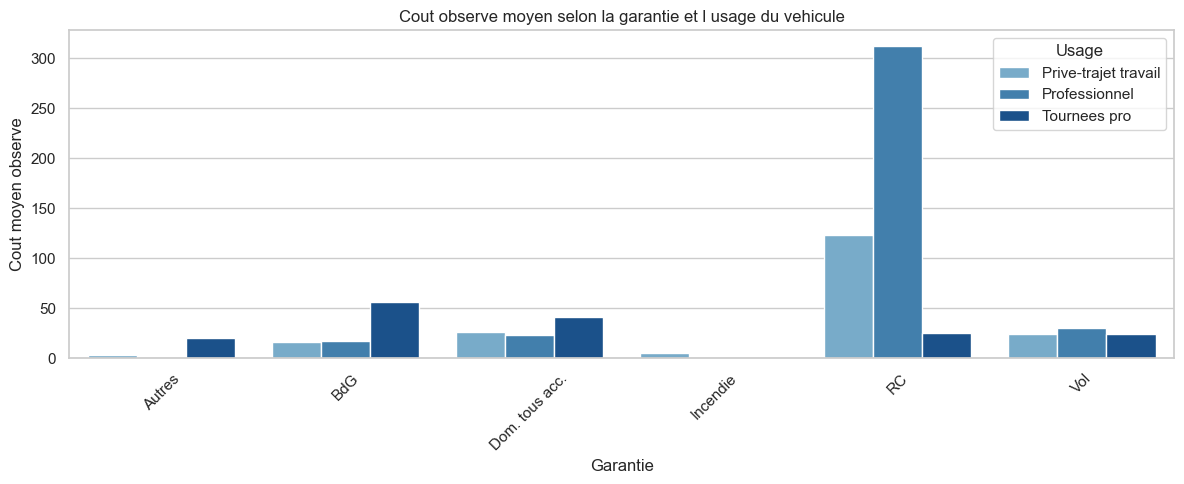

In [125]:
# Croisement 3 : cout observe moyen selon la garantie et l usage du vehicule
plt.figure(figsize=(12, 5))
sns.barplot(
    data=tarif_garantie_usage,
    x='Guarantee',
    y='Cout_observe_moyen',
    hue='VehUsage',
    palette=['#6baed6', '#3182bd', '#08519c']
)
plt.title('Cout observe moyen selon la garantie et l usage du vehicule')
plt.xlabel('Garantie')
plt.ylabel('Cout moyen observe')
plt.xticks(rotation=45)
plt.legend(title='Usage')
plt.tight_layout()
plt.show()

Ce dernier graphique permet de rapprocher directement la logique tarifaire de la réalité observée. Lorsque les segments affichant les coûts observés les plus élevés correspondent aussi à des primes tarifaires plus fortes, cela constitue un signal de cohérence de la tarification proposée. Dans ce portefeuille, la combinaison de certaines garanties avec l'usage professionnel ressort clairement comme plus coûteuse.

Cette étape de tarification met en évidence plusieurs résultats intéressants pour le rapport :

- la **garantie de responsabilité civile (RC)** concentre les niveaux tarifaires prédits les plus élevés, ce qui est cohérent avec son poids dans la charge de sinistralité ;
- les croisements **garantie x âge** montrent que certaines garanties restent plus sensibles aux profils jeunes ou intermédiaires ;
- les croisements **garantie x usage** soulignent que l’usage professionnel tend à tirer certaines primes tarifaires vers le haut, en cohérence avec des coûts observés plus élevés.

Ces visualisations rendent la tarification plus lisible : on ne se limite plus à une moyenne globale, mais on observe directement comment la prime tarifaire varie selon des segments de risque concrets.


# V. Conclusion générale

Ce projet a permis de conduire une etude complete sur un portefeuille d'assurance automobile, depuis le **traitement des donnees** jusqu'a une **premiere proposition de tarification**.

Dans un premier temps, les differentes bases ont ete nettoyees, verifiees et harmonisees afin de construire une table unique d'analyse `fremotor`, exploitable au niveau `(IDpol, Year, Guarantee)`. Ce travail etait indispensable pour garantir la qualite statistique des etapes suivantes.

L'analyse descriptive a ensuite mis en evidence plusieurs enseignements metier :

- le portefeuille est globalement **peu sinistre**, avec une forte majorite d'observations sans cout ;
- la garantie **responsabilité Civil** occupe une place centrale, a la fois en termes de frequence, de cout et de primes ;
- certaines caracteristiques du conducteur et du vehicule, comme l'age, l'usage, le carburant ou la puissance, semblent influencer la sinistralite et la structure tarifaire.

Dans un second temps, plusieurs modeles predictifs ont ete ajustes. La **regression logistique** a permis de modeliser la probabilite d'avoir un sinistre, le **modele de Poisson** la frequence des sinistres, le **modele Gamma** la severite moyenne, et un **modele Tweedie** a servi de comparaison pour la prediction directe du cout. Cote machine learning non parametrique, nous avons volontairement retenu seulement **Random Forest** et **Gradient Boosting**, en cohérence avec  avec l'objectif de conserver une comparaison lisible.

Enfin, la construction d'une **prime pure predite**, puis d'une **prime tarifaire indicative** via un chargement global, a permis de relier l'analyse statistique a une problematique concrete de tarification. Cette approche constitue une premiere base de travail interessante pour une insurtech, en attendant un enrichissement futur du modele avec davantage de donnees, d'ajustements et de contraintes metier.

En prolongement naturel du projet, il serait pertinent de :

1. affiner la tarification par segment de risque ;
2. comparer plus finement la structure tarifaire observee et la tarification predite ;
3. etudier plus avant l'interpretabilite locale des modeles non parametriques ;
